# Aprendizado por Reforço na prática

**Tópicos Especiais em Aprendizado de Máquina · CEFET-MG**
Seminário: Aprendizado por Reforço

Integrantes: Daniel Alves Sanches · Eduardo Henrique Queiroz Almeida · Elcio Costa Amorim Neto · João Francisco Teles da Silva · Matheus Emanuel da Silva · Samuel Silva Gomes

---

> **Durante a apresentação:** use *Executar tudo* (*Run All*) uma vez, logo no início. Em 2 a 4 minutos todas as partes ficam prontas, e você só acompanha os resultados à medida que os slides chegam a cada parte.

Este notebook acompanha os slides do seminário. Cada parte corresponde a um bloco da apresentação. **Execute as células em ordem**: as partes reaproveitam funções das anteriores (o ambiente `Armazem` vem da Parte 1, `escolher_eps_greedy` da Parte 5, `treinar` e os resultados de treino da Parte 6, o `CartPole` da Parte 9 e a DQN da Parte 10).

| Parte | Conteúdo | Tempo aprox. de execução |
|---|---|---|
| 0 | Configuração e funções de desenho | < 1 s |
| 1 | O problema do robô no armazém (MDP) | < 1 s |
| 2 | Retorno descontado e o papel de γ | < 1 s |
| 3 | Exploração e explotação: bandido de 10 braços | ~ 2 s |
| 4 | Programação dinâmica: iteração de valor | < 1 s |
| 5 | Diferença temporal passo a passo | ~ 1 s |
| 6 | SARSA vs. Q-Learning no armazém, variando ε e γ | ~ 30 a 70 s |
| 7 | Avaliação com protocolo (sementes, ruído, intervalos) | ~ 5 a 10 s |
| 8 | Dyna-Q: planejamento com modelo aprendido | ~ 5 a 10 s |
| 9 | Por que tabelas grandes são um problema | ~ 30 a 50 s |
| 10 | DQN implementada em NumPy (CartPole) | ~ 20 a 35 s |
| 11 | Gradiente de política (REINFORCE, 5 sementes) | ~ 12 a 25 s |
| 12 | Desenho de recompensa e *reward hacking* | ~ 5 s |

**Dependências:** apenas `numpy` e `matplotlib`. Os ambientes foram implementados aqui mesmo para que o notebook rode em qualquer máquina, sem instalar `gymnasium` ou bibliotecas de redes neurais. O CartPole das Partes 9 a 11 reproduz a dinâmica do `CartPole-v1` do Gymnasium (Towers et al., 2024).

Todas as sementes aleatórias são fixas. As Partes 1 a 9 e 12 reproduzem exatamente os números dos slides em qualquer máquina. As Partes 10 e 11 (DQN e REINFORCE) fazem milhares de operações em ponto flutuante, e diferenças mínimas de arredondamento entre máquinas ou versões do NumPy se acumulam ao longo do treino: os números podem sair um pouco diferentes dos slides, mas o comportamento qualitativo é o mesmo. O tempo total de execução fica entre 2 e 4 minutos, conforme a máquina.

## Parte 0 · Configuração

Importações, paleta de cores usada em todos os gráficos e funções auxiliares de desenho. Nada de aprendizado por reforço acontece aqui.

In [1]:
import os, time, logging
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# Paleta única para o notebook inteiro
COR = {
    "tinta":   "#1F2328",  # texto
    "cinza":   "#6B7280",  # texto secundário
    "grade":   "#E5E7EB",  # linhas de grade
    "piso":    "#F3F4F6",  # piso do armazém
    "estante": "#4B5563",  # prateleiras (obstáculos)
    "doca":    "#E4572E",  # doca de carga (perigo)
    "sarsa":   "#0F766E",  # SARSA
    "qlearn":  "#E4572E",  # Q-Learning
    "dyna":    "#7C3AED",  # Dyna-Q
    "dqn":     "#2F5DA8",  # DQN
    "reinf":   "#B45309",  # REINFORCE
    "meta":    "#15803D",  # ponto de entrega
}
# Mapa de calor divergente: laranja = valores negativos, branco = zero, verde-azulado = positivos
MAPA_CALOR = LinearSegmentedColormap.from_list("calor", ["#E4572E", "#FDE7DF", "#FFFFFF", "#CCEDE8", "#0F766E"])

plt.rcParams.update({
    "font.family": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 13, "axes.titlesize": 14, "axes.titleweight": "semibold",
    "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.labelcolor": COR["tinta"], "axes.edgecolor": "#9CA3AF",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.8,
    "xtick.color": COR["cinza"], "ytick.color": COR["cinza"],
    "legend.frameon": False, "figure.dpi": 110, "savefig.bbox": "tight", "axes.axisbelow": True,
})

# Se a variável de ambiente RL_FIGURAS apontar para uma pasta, as figuras também são salvas lá
PASTA_FIG = os.environ.get("RL_FIGURAS")

def _numero_br(v, texto):
    """Converte o rótulo de um eixo para o formato brasileiro: 0.5 -> 0,5 e 10000 -> 10.000."""
    t = texto.replace("−", "-")
    try:
        float(t)
    except ValueError:
        return texto
    if abs(v) >= 1000 and float(v).is_integer():
        s = f"{int(abs(v)):,}".replace(",", ".")
    else:
        s = t.lstrip("-").replace(".", ",")
    return ("−" if v < 0 else "") + s

def formato_br(fig):
    """Aplica vírgula decimal e ponto de milhar aos eixos lineares da figura."""
    fig.canvas.draw()
    for ax in fig.axes:
        if not ax.axison:
            continue
        for eixo, escala in ((ax.xaxis, ax.get_xscale()), (ax.yaxis, ax.get_yscale())):
            if escala != "linear" or not eixo.get_visible():
                continue
            lim = sorted(ax.get_xlim() if eixo is ax.xaxis else ax.get_ylim())
            locs = [v for v in eixo.get_majorticklocs() if lim[0] - 1e-9 <= v <= lim[1] + 1e-9]
            textos = eixo.get_major_formatter().format_ticks(locs)
            eixo.set_ticks(locs, [_numero_br(v, t) for v, t in zip(locs, textos)])

def mostrar(fig, nome):
    formato_br(fig)
    if PASTA_FIG:
        fig.savefig(os.path.join(PASTA_FIG, nome + ".png"), dpi=220, facecolor="white")
    plt.show()

def media_movel(x, janela):
    x = np.asarray(x, float)
    return np.convolve(x, np.ones(janela) / janela, mode="valid")

def ic95_bootstrap(amostras, n_boot=5000, seed=0):
    """Intervalo de confiança de 95% da média por bootstrap percentil."""
    rng = np.random.default_rng(seed)
    amostras = np.asarray(amostras, float)
    medias = rng.choice(amostras, (n_boot, len(amostras))).mean(1)
    return amostras.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

print("NumPy", np.__version__, "| Matplotlib", plt.matplotlib.__version__)

NumPy 2.4.4 | Matplotlib 3.11.1


## Parte 1 · O problema: um robô de entrega no armazém

Um robô precisa levar um pacote do ponto de **início** até o ponto de **entrega**. O armazém tem prateleiras (obstáculos) e, na faixa inferior, uma **doca de carga** desnivelada. Se o robô entra na doca, a carga é perdida e ele volta ao início.

O caminho mais curto passa colado à doca, o que cria um conflito entre chegar rápido e correr risco.

### Modelagem como MDP $(\mathcal{S}, \mathcal{A}, P, R, \gamma)$

| Elemento | No armazém |
|---|---|
| Estados $\mathcal{S}$ | posição $(linha, coluna)$ do robô na grade 6 × 10. A tabela tem 60 linhas, mas só 40 células são ocupáveis (as 12 prateleiras e as 8 células da doca nunca são estados do robô) |
| Ações $\mathcal{A}$ | cima, baixo, esquerda, direita |
| Transição $P(s' \mid s,a)$ | o robô anda uma célula; se bater em prateleira ou parede, fica no lugar. Opcionalmente, com probabilidade `ruido`, executa uma ação aleatória (falha de atuador) |
| Recompensa $R$ | −1 por passo · +10 ao entregar (fim do episódio) · −100 ao cair na doca (volta ao início) |
| Desconto $\gamma$ | definido em cada experimento |

A estrutura (penalidade grande ao lado do caminho ótimo) é inspirada no exemplo *Cliff Walking* de Sutton e Barto (2018, Exemplo 6.6). O armazém, as prateleiras e os valores de recompensa são uma adaptação nossa.

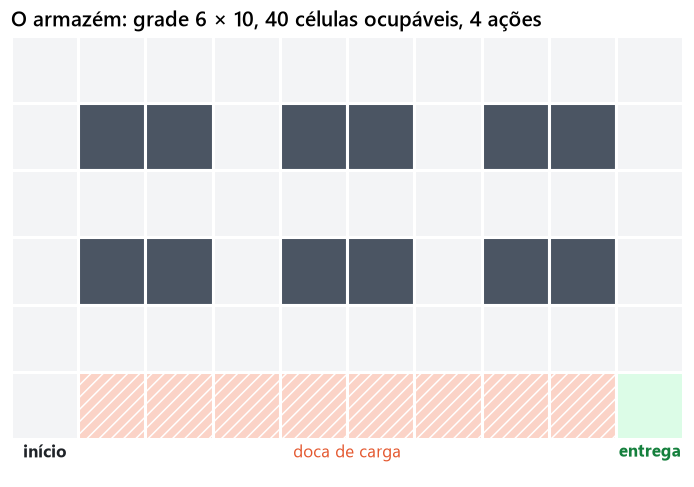

Estados: 60 | Ações: 4 | Entradas da tabela Q: 240


In [2]:
MAPA_ARMAZEM = [
    "..........",
    ".##.##.##.",
    "..........",
    ".##.##.##.",
    "..........",
    "SDDDDDDDDG",
]
# S = início, G = entrega, # = prateleira, D = doca de carga, . = piso livre

ACOES = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # cima, baixo, esquerda, direita
NOMES_ACOES = ["cima", "baixo", "esquerda", "direita"]
SETAS = {0: (0, -0.32), 1: (0, 0.32), 2: (-0.32, 0), 3: (0.32, 0)}   # (dx, dy) para desenho


class Armazem:
    """Ambiente em grade com a mesma interface básica do Gymnasium: reset() e step(a)."""

    def __init__(self, mapa=MAPA_ARMAZEM, r_passo=-1.0, r_meta=10.0, r_doca=-100.0,
                 ruido=0.0, max_passos=500, seed=None):
        self.grade = np.array([list(linha) for linha in mapa])
        self.L, self.C = self.grade.shape
        self.inicio = tuple(int(v) for v in np.argwhere(self.grade == "S")[0])
        self.meta = tuple(int(v) for v in np.argwhere(self.grade == "G")[0])
        self.r_passo, self.r_meta, self.r_doca = r_passo, r_meta, r_doca
        self.ruido, self.max_passos = ruido, max_passos
        self.n_estados, self.n_acoes = self.L * self.C, 4
        self.rng = np.random.default_rng(seed)

    # conversões entre posição (linha, coluna) e índice inteiro do estado
    def indice(self, p):  return p[0] * self.C + p[1]
    def posicao(self, s): return divmod(int(s), self.C)

    def transicao(self, p, a):
        """Modelo determinístico: devolve (próxima posição, recompensa, terminal, caiu_na_doca)."""
        dl, dc = ACOES[a]
        n = (p[0] + dl, p[1] + dc)
        if not (0 <= n[0] < self.L and 0 <= n[1] < self.C) or self.grade[n] == "#":
            n = p                                    # bateu: fica no lugar
        if self.grade[n] == "D":
            return self.inicio, self.r_doca, False, True
        if self.grade[n] == "G":
            return n, self.r_meta, True, False
        return n, self.r_passo, False, False

    def reset(self):
        self.p, self.t = self.inicio, 0
        return self.indice(self.p)

    def step(self, a):
        if self.ruido > 0 and self.rng.random() < self.ruido:
            a = int(self.rng.integers(4))            # falha de atuador
        self.p, r, terminal, caiu = self.transicao(self.p, a)
        self.t += 1
        truncado = self.t >= self.max_passos         # limite de tempo (não é falha)
        return self.indice(self.p), r, terminal, truncado, caiu


def barra_compartilhada(fig, axs, vmin, vmax):
    """Uma barra de cores horizontal, abaixo dos painéis, com a mesma escala centrada em zero."""
    norma = TwoSlopeNorm(vcenter=0.0, vmin=min(vmin, -1e-6), vmax=max(vmax, 1e-6))
    sm = plt.cm.ScalarMappable(norm=norma, cmap=MAPA_CALOR)
    cb = fig.colorbar(sm, ax=list(axs), orientation="horizontal", fraction=0.06, pad=0.04, aspect=60)
    marcas = sorted(set([round(vmin), round(vmin / 2), 0, round(vmax / 2), round(vmax)]))
    cb.set_ticks(marcas, labels=[str(m).replace("-", "−") for m in marcas])
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=11)


def desenhar_armazem(env, ax, valores=None, politica=None, rotas=(), titulo=None,
                     escala=None, mostrar_valores=False, barra=True):
    """Desenha a grade. valores: vetor por estado (mapa de calor). politica: ação por estado.
    rotas: lista de (lista_de_posicoes, cor, rotulo)."""
    L, C = env.L, env.C
    ax.set_xlim(-0.5, C - 0.5); ax.set_ylim(L - 0.5 + 0.55, -0.5)
    ax.set_aspect("equal"); ax.axis("off")
    vmin, vmax = escala if escala else (None, None)
    norma = None
    if valores is not None:
        livres = [env.indice((i, j)) for i in range(L) for j in range(C) if env.grade[i, j] in ".S"]
        v = np.asarray(valores, float)
        vmin = v[livres].min() if vmin is None else vmin
        vmax = v[livres].max() if vmax is None else vmax
        # escala centrada em zero: branco = 0, laranja = negativo, verde-azulado = positivo
        norma = TwoSlopeNorm(vcenter=0.0, vmin=min(vmin, -1e-6), vmax=max(vmax, 1e-6))
    for i in range(L):
        for j in range(C):
            c = env.grade[i, j]
            if c == "#":
                cor = COR["estante"]
            elif c == "D":
                cor = "#FBD3C7"
            elif c == "G":
                cor = "#DCFCE7"
            elif valores is not None:
                cor = MAPA_CALOR(norma(valores[env.indice((i, j))]))
            else:
                cor = COR["piso"]
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=cor,
                                   edgecolor="white", linewidth=2,
                                   hatch="///" if c == "D" else None))
            # rótulos de início e entrega ficam abaixo da grade, para não serem cobertos pelas rotas
            if c == "S":
                ax.text(j, L - 0.5 + 0.08, "início", ha="center", va="top", fontsize=11,
                        color=COR["tinta"], weight="bold")
            elif c == "G":
                ax.text(j, L - 0.5 + 0.08, "entrega", ha="center", va="top", fontsize=11,
                        color=COR["meta"], weight="bold")
            if mostrar_valores and valores is not None and c in ".S":
                ax.text(j, i - 0.25, f"{valores[env.indice((i, j))]:.1f}".replace(".", ",").replace("-", "−"),
                        ha="center", va="center", fontsize=10, color=COR["tinta"])
            if politica is not None and c in ".S":
                dx, dy = SETAS[int(politica[env.indice((i, j))])]
                cy = i + (0.15 if mostrar_valores else 0)
                ax.add_patch(FancyArrowPatch((j - dx * 0.75, cy - dy * 0.75), (j + dx * 0.75, cy + dy * 0.75),
                                             arrowstyle="-|>", mutation_scale=10,
                                             color=COR["tinta"], linewidth=1.2))
    if (env.grade == "D").any():
        ax.text(C / 2 - 0.5, L - 0.5 + 0.08, "doca de carga", ha="center", va="top",
                fontsize=11, color=COR["doca"])
    if valores is not None and barra:
        sm = plt.cm.ScalarMappable(norm=norma, cmap=MAPA_CALOR)
        cb = ax.figure.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
        cb.outline.set_visible(False); cb.ax.tick_params(labelsize=10)
    for k, (rota, cor, rotulo) in enumerate(rotas):
        ys = [p[0] for p in rota]; xs = [p[1] for p in rota]
        desloc = (k - (len(rotas) - 1) / 2) * 0.12
        ax.plot(np.array(xs) + desloc, np.array(ys) + desloc, color=cor, linewidth=3,
                solid_capstyle="round", label=rotulo, zorder=5)
        ax.plot(xs[-1] + desloc, ys[-1] + desloc, "o", color=cor, markersize=7, zorder=6)
    if rotas:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(rotas), fontsize=11)
    if titulo:
        ax.set_title(titulo, loc="left")


env = Armazem()
fig, ax = plt.subplots(figsize=(8, 5.2))
desenhar_armazem(env, ax, titulo="O armazém: grade 6 × 10, 40 células ocupáveis, 4 ações")
mostrar(fig, "p1_armazem")
print(f"Estados: {env.n_estados} | Ações: {env.n_acoes} | Entradas da tabela Q: {env.n_estados * env.n_acoes}")

**Leitura da figura.** As células cinza-escuras são prateleiras, a faixa hachurada é a doca. Existem duas famílias de rotas:

* **rota curta (11 passos):** sobe uma célula e segue pela linha imediatamente acima da doca;
* **rota afastada (15 passos):** sobe até a linha do meio, atravessa e desce.

Com o robô sem falhas, a rota curta é a melhor. Quando há chance de uma ação sair errada, andar colado à doca passa a ter custo esperado alto. Na Parte 6, SARSA e Q-Learning escolhem rotas diferentes por causa disso: lá, a "ação que sai errada" é a própria exploração ε-greedy do agente durante o treino. Na Parte 7, a mesma situação aparece como falha de atuador do robô.

## Parte 2 · Retorno descontado: o que o agente maximiza

O agente não maximiza a recompensa do próximo passo, e sim o **retorno**:

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$$

O fator $\gamma \in [0,1]$ define quanto uma recompensa que chega $k$ passos depois vale hoje: ela é multiplicada por $\gamma^k$ (Sutton; Barto, 2018, seção 3.3).

Primeiro, o exemplo do material da disciplina: recompensas $(-1, -1, +10)$ com $\gamma = 0{,}9$.

In [3]:
def retorno(recompensas, gamma):
    """G_0 = soma de gamma^k * R_{k+1}."""
    return sum((gamma ** k) * r for k, r in enumerate(recompensas))

seq = [-1, -1, 10]
print("Parcelas com gamma = 0,9:")
for k, r in enumerate(seq):
    print(f"  k={k}:  0.9^{k} x ({r:+d}) = {0.9 ** k * r:+.2f}")
print(f"  G_0 = {retorno(seq, 0.9):.2f}\n")

for g in [0.0, 0.5, 0.9, 1.0]:
    print(f"gamma = {g:<4} ->  G_0 = {retorno(seq, g):+.2f}")

Parcelas com gamma = 0,9:
  k=0:  0.9^0 x (-1) = -1.00
  k=1:  0.9^1 x (-1) = -0.90
  k=2:  0.9^2 x (+10) = +8.10
  G_0 = 6.20

gamma = 0.0  ->  G_0 = -1.00
gamma = 0.5  ->  G_0 = +1.00
gamma = 0.9  ->  G_0 = +6.20
gamma = 1.0  ->  G_0 = +8.00


**Interpretação.** Com $\gamma = 0$ o agente é "míope": só enxerga o −1 imediato e o retorno é −1. Com $\gamma = 0{,}5$ a recompensa +10, que está a dois passos, já vale 2,5 e o retorno fica positivo (+1,0). Com $\gamma = 0{,}9$ chegamos aos 6,2 do slide. O mesmo histórico de recompensas pode parecer ruim ou bom dependendo de $\gamma$.

A seguir, o retorno da rota curta e o da rota afastada do armazém.

 gamma | rota curta | rota afastada
   0.5 |      -1.99 |         -2.00
   0.9 |      -3.03 |         -5.42
  0.95 |      -2.04 |         -5.37
  0.99 |      -0.52 |         -4.44
   1.0 |       0.00 |         -4.00


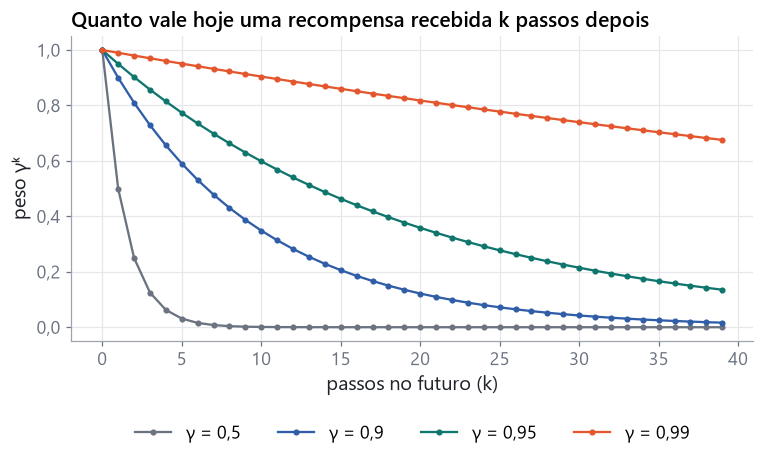

In [4]:
rota_curta    = [-1] * 10 + [10]     # 10 passos comuns e a entrega no 11º
rota_afastada = [-1] * 14 + [10]     # 14 passos comuns e a entrega no 15º

print(f"{'gamma':>6} | {'rota curta':>10} | {'rota afastada':>13}")
for g in [0.5, 0.9, 0.95, 0.99, 1.0]:
    print(f"{g:>6} | {retorno(rota_curta, g):>10.2f} | {retorno(rota_afastada, g):>13.2f}")

fig, ax = plt.subplots(1, 1, figsize=(8, 3.6))
k = np.arange(0, 40)
for g, cor in [(0.5, COR["cinza"]), (0.9, COR["dqn"]), (0.95, COR["sarsa"]), (0.99, COR["qlearn"])]:
    ax.plot(k, g ** k, marker="o", markersize=3, color=cor, label=f"γ = {g}".replace(".", ","))
ax.set_xlabel("passos no futuro (k)"); ax.set_ylabel("peso γᵏ")
ax.set_title("Quanto vale hoje uma recompensa recebida k passos depois", loc="left")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
mostrar(fig, "p2_pesos_gamma")

**Interpretação.** Sem risco, a rota curta sempre tem retorno maior, para qualquer $\gamma$; o desconto muda o **horizonte efetivo**. Os valores não variam de forma monotônica com $\gamma$ (−3,03 com 0,9 e −2,04 com 0,95, por exemplo) porque $\gamma$ maior aumenta o peso dos custos −1 e também o peso do +10 final; qual dos dois efeitos domina depende de quantos passos há até a entrega. Com $\gamma = 0{,}5$, uma recompensa a 10 passos pesa menos de 0,1% do valor original; com $\gamma = 0{,}99$, ainda pesa cerca de 90%. Na prática, $\gamma$ próximo de 1 faz o agente planejar mais longe, mas também deixa o aprendizado mais lento, porque a informação precisa se propagar por mais passos.

Para tarefas contínuas (sem fim), $\gamma < 1$ também garante que a soma seja finita: se $|R| \le R_{max}$, então $|G_t| \le R_{max}/(1-\gamma)$ (Sutton; Barto, 2018, seção 3.3).

## Parte 3 · Exploração vs. explotação: o bandido de 10 braços

Antes de voltar ao armazém, isolamos o dilema central do RL num problema sem estados: 10 máquinas caça-níqueis, cada uma com uma recompensa média desconhecida. A cada rodada o agente puxa uma alavanca.

* **Explotar**: puxar a alavanca que parece melhor até agora.
* **Explorar**: puxar outra para estimar melhor seu valor.

Reproduzimos o experimento clássico de Sutton e Barto (2018, seção 2.3): 2.000 problemas sorteados, 1.000 rodadas cada, médias reais $q_*(a) \sim \mathcal{N}(0,1)$ e recompensa $\mathcal{N}(q_*(a), 1)$. Comparamos o agente guloso ($\varepsilon = 0$) com $\varepsilon$-greedy.

tempo: 1.4 s


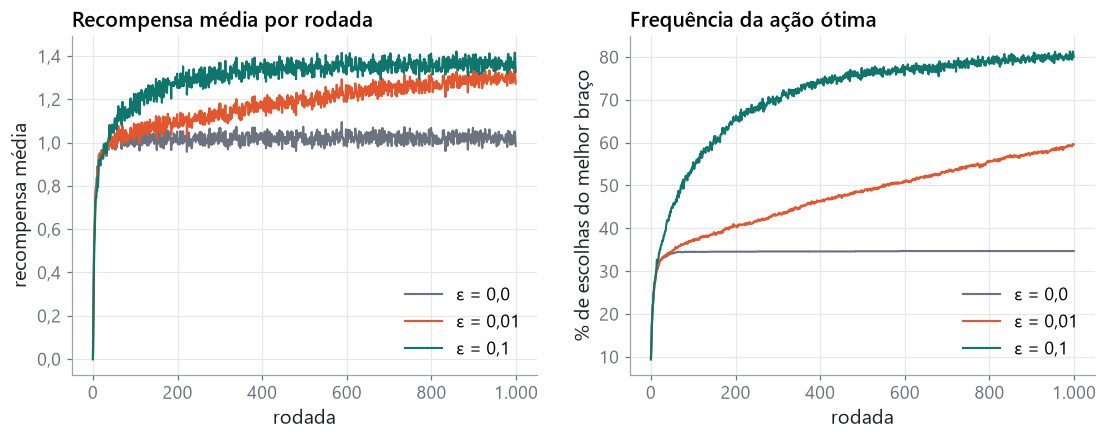

ε = 0.0   recompensa média (últimas 100) = 1.02 | ação ótima = 35%
ε = 0.01  recompensa média (últimas 100) = 1.30 | ação ótima = 58%
ε = 0.1   recompensa média (últimas 100) = 1.36 | ação ótima = 80%


In [5]:
def bandido(eps, n_problemas=2000, n_passos=1000, k=10, seed=0):
    rng = np.random.default_rng(seed)
    q_real = rng.normal(0, 1, (n_problemas, k))        # valor verdadeiro de cada braço
    melhor = q_real.argmax(1)
    Q = np.zeros((n_problemas, k))                      # estimativas do agente
    N = np.zeros((n_problemas, k))                      # contagem de puxadas
    linhas = np.arange(n_problemas)
    rec_media, pct_otima = np.zeros(n_passos), np.zeros(n_passos)
    for t in range(n_passos):
        # ação gulosa com desempate aleatório
        gulosa = (Q + rng.random(Q.shape) * 1e-6).argmax(1)
        aleatoria = rng.integers(0, k, n_problemas)
        a = np.where(rng.random(n_problemas) < eps, aleatoria, gulosa)
        r = rng.normal(q_real[linhas, a], 1)
        N[linhas, a] += 1
        Q[linhas, a] += (r - Q[linhas, a]) / N[linhas, a]   # média incremental
        rec_media[t] = r.mean(); pct_otima[t] = (a == melhor).mean() * 100
    return rec_media, pct_otima

t0 = time.time()
resultados = {eps: bandido(eps) for eps in [0.0, 0.01, 0.1]}
print(f"tempo: {time.time() - t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
cores = {0.0: COR["cinza"], 0.01: COR["qlearn"], 0.1: COR["sarsa"]}
for eps, (rm, po) in resultados.items():
    rot = f"ε = {eps}".replace(".", ",")
    axs[0].plot(rm, color=cores[eps], label=rot, linewidth=1.4)
    axs[1].plot(po, color=cores[eps], label=rot, linewidth=1.4)
axs[0].set(xlabel="rodada", ylabel="recompensa média"); axs[0].set_title("Recompensa média por rodada", loc="left")
axs[1].set(xlabel="rodada", ylabel="% de escolhas do melhor braço"); axs[1].set_title("Frequência da ação ótima", loc="left")
axs[0].legend(); axs[1].legend()
mostrar(fig, "p3_bandido")

for eps, (rm, po) in resultados.items():
    print(f"ε = {eps:<5} recompensa média (últimas 100) = {rm[-100:].mean():.2f} | "
          f"ação ótima = {po[-100:].mean():.0f}%")

**Interpretação.**

* O agente **guloso** (cinza) melhora rápido no começo e estaciona: ele fica preso ao primeiro braço que pareceu bom. Nas últimas rodadas, só 35% das escolhas são do melhor braço.
* Com **ε = 0,1** o agente gasta 10% das rodadas explorando. Ele descobre o melhor braço mais cedo e termina com a maior recompensa média, com cerca de 80% das escolhas no melhor braço. Esse número nunca passaria de 91% ($0{,}9 + 0{,}1/10$), porque o agente continua explorando para sempre.
* Com **ε = 0,01** a melhora é lenta, mas a longo prazo superaria ε = 0,1 (Sutton; Barto, 2018, seção 2.3).

Esse é o motivo de se usar **decaimento de ε**: explorar muito no início e pouco no fim. O ε-greedy é a forma mais simples de explorar; alternativas como UCB (Auer; Cesa-Bianchi; Fischer, 2002) e amostragem de Thompson (Thompson, 1933) direcionam a exploração para as ações mais incertas.

## Parte 4 · Quando o modelo é conhecido: iteração de valor

Se conhecemos $P$ e $R$, não precisamos interagir com o ambiente: basta aplicar repetidamente a **equação de otimalidade de Bellman** a todos os estados (programação dinâmica, Bellman, 1957):

$$V_{k+1}(s) = \max_a \sum_{s'} P(s' \mid s,a)\,\big[R(s,a,s') + \gamma V_k(s')\big]$$

No armazém sem ruído a transição é determinística, então a soma tem um único termo. Vamos ver os valores "se espalhando" a partir da entrega.

Convergiu em 15 iterações.


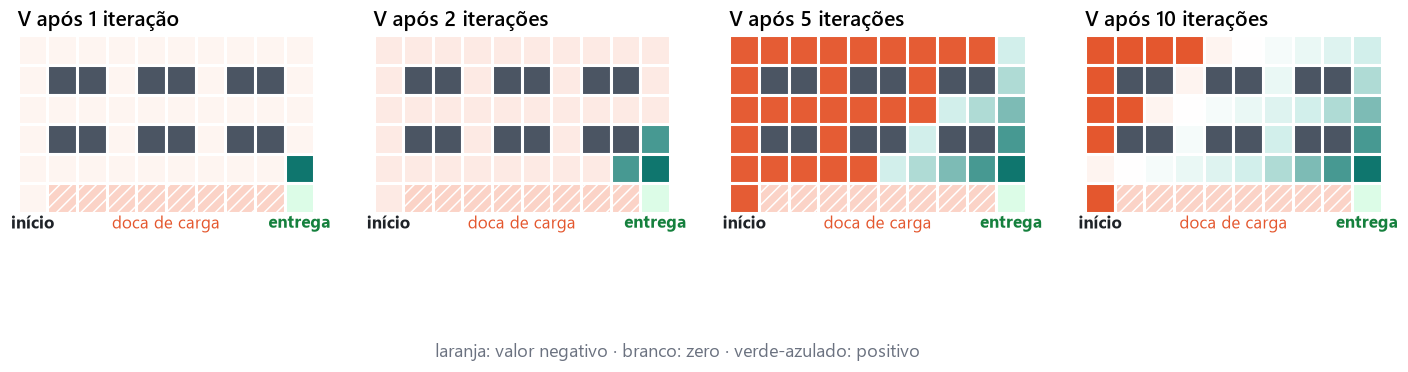

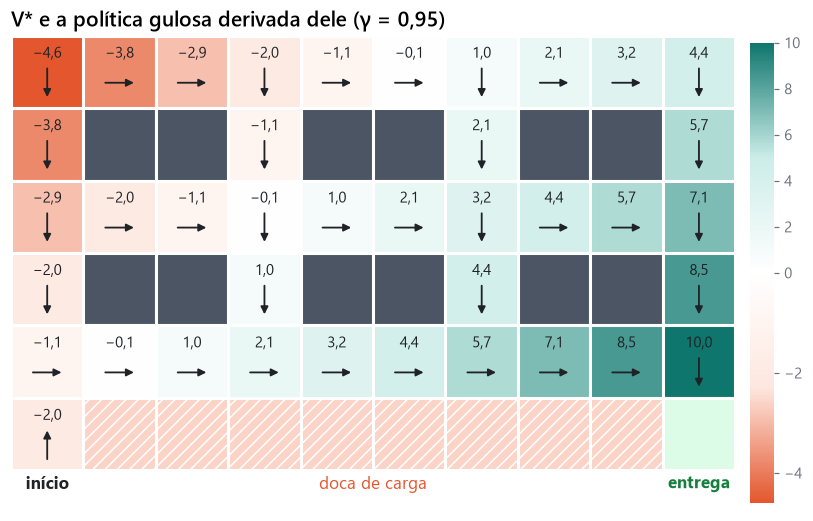

In [6]:
def iteracao_de_valor(env, gamma=0.95, tol=1e-6, guardar=(1, 2, 5, 10)):
    V = np.zeros(env.n_estados)
    fotos = {0: V.copy()}
    livres = [(i, j) for i in range(env.L) for j in range(env.C) if env.grade[i, j] in ".S"]
    for k in range(1, 1000):
        V_novo = V.copy()
        for p in livres:
            candidatos = []
            for a in range(4):
                p2, r, term, _ = env.transicao(p, a)
                candidatos.append(r + (0 if term else gamma * V[env.indice(p2)]))
            V_novo[env.indice(p)] = max(candidatos)
        delta = np.abs(V_novo - V).max()
        V = V_novo
        if k in guardar: fotos[k] = V.copy()
        if delta < tol: break
    fotos["final"] = V.copy()
    # política gulosa em relação a V
    pi = np.zeros(env.n_estados, int)
    for p in livres:
        q = []
        for a in range(4):
            p2, r, term, _ = env.transicao(p, a)
            q.append(r + (0 if term else gamma * V[env.indice(p2)]))
        pi[env.indice(p)] = int(np.argmax(q))
    return V, pi, fotos, k

env = Armazem()
V, pi_otima, fotos, n_iter = iteracao_de_valor(env)
print(f"Convergiu em {n_iter} iterações.")

fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
escala = (fotos["final"][[env.indice((i, j)) for i in range(env.L) for j in range(env.C)
                          if env.grade[i, j] in '.S']].min(), 10)
for ax, k in zip(axs, [1, 2, 5, 10]):
    desenhar_armazem(env, ax, valores=fotos[k], escala=escala, barra=False,
                     titulo=f"V após {k} " + ("iteração" if k == 1 else "iterações"))
fig.text(0.5, 0.02, "laranja: valor negativo · branco: zero · verde-azulado: positivo", ha="center", fontsize=12, color=COR["cinza"])
mostrar(fig, "p4_iteracao_valor")

fig, ax = plt.subplots(figsize=(9, 5.6))
desenhar_armazem(env, ax, valores=V, politica=pi_otima, escala=escala, mostrar_valores=True,
                 titulo="V* e a política gulosa derivada dele (γ = 0,95)")
mostrar(fig, "p4_valor_politica")

**Interpretação.**

* Na iteração 1, só a célula logo acima da entrega "sabe" que ela existe (valor +10): é a única de onde um passo chega lá, porque a vizinha da esquerda é doca. Todas as outras têm −1, o custo de um passo.
* A cada iteração, a informação recua **uma célula**: é a recursão de Bellman em ação, o valor de um estado é montado a partir do valor dos vizinhos.
* No mapa final, as setas formam a **política ótima**: de qualquer célula, seguir a seta leva ao destino pelo menor número de passos. A partir do início, ela usa a rota curta, colada à doca, porque neste modelo não há ruído.
* O número em cada célula é $V^*(s)$: quanto mais longe da entrega, menor.

**Limitação.** Isso só foi possível porque escrevemos a função `transicao`, ou seja, o agente conhecia o modelo do mundo. Nas próximas partes o agente não tem acesso a ela: precisa aprender interagindo (métodos *model-free*).

## Parte 5 · Diferença temporal passo a passo

Sem modelo, o agente estima $Q(s,a)$ a partir de transições observadas $(s, a, r, s')$. A cada transição ele calcula um **alvo** e move a estimativa na direção dele:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\underbrace{y}_{\text{alvo}} - Q(s,a)\big]$$

| Método | Alvo $y$ |
|---|---|
| SARSA | $r + \gamma\,Q(s', a')$, com $a'$ = ação que a política **realmente** vai executar |
| Q-Learning | $r + \gamma\,\max_{a'} Q(s', a')$, a **melhor** ação estimada |

Se $s'$ é terminal, ambos usam $y = r$. O SARSA foi proposto por Rummery e Niranjan (1994) e o Q-Learning por Watkins (1989), com prova de convergência em Watkins e Dayan (1992).

Reproduzimos o exemplo numérico do material: $Q(s,a)=2$, $r=3$, $\gamma=0{,}9$, $\alpha=0{,}2$.

In [7]:
def atualizacao_td(q_atual, r, gamma, alpha, valor_prox, terminal=False):
    alvo = r if terminal else r + gamma * valor_prox
    erro_td = alvo - q_atual
    return alvo, erro_td, q_atual + alpha * erro_td

for nome, valor_prox in [("SARSA      (Q(s',a') = 4)", 4), ("Q-Learning (max Q(s',·) = 7)", 7)]:
    y, d, q = atualizacao_td(2, 3, 0.9, 0.2, valor_prox)
    print(f"{nome}: alvo = 3 + 0,9 x {valor_prox} = {y:.2f} | erro TD = {d:.2f} | Q novo = 2 + 0,2 x {d:.2f} = {q:.2f}")
y, d, q = atualizacao_td(2, 3, 0.9, 0.2, None, terminal=True)
print(f"Se s' fosse terminal: alvo = r = {y:.2f} | Q novo = {q:.2f}")

SARSA      (Q(s',a') = 4): alvo = 3 + 0,9 x 4 = 6.60 | erro TD = 4.60 | Q novo = 2 + 0,2 x 4.60 = 2.92
Q-Learning (max Q(s',·) = 7): alvo = 3 + 0,9 x 7 = 9.30 | erro TD = 7.30 | Q novo = 2 + 0,2 x 7.30 = 3.46
Se s' fosse terminal: alvo = r = 3.00 | Q novo = 2.20


**Interpretação.** As duas regras partem do mesmo $Q = 2$ e da mesma recompensa, mas o Q-Learning sobe mais (3,46 contra 2,92) porque o alvo dele usa o melhor valor do próximo estado, enquanto o SARSA usa o valor da ação que vai de fato executar. O $\alpha = 0{,}2$ faz cada atualização andar só 20% do caminho até o alvo: o agente não descarta o que já sabia por causa de uma única experiência.

Agora vemos o mesmo mecanismo acontecendo no armazém. Mostramos $\max_a Q(s,a)$ em cada célula depois de alguns episódios de Q-Learning.

Primeiras 6 atualizações do episódio 1:
  estado      ação     r  Q antes    alvo  Q depois
  (5, 0)   direita  -100     0.00 -100.00    -50.00
  (5, 0)  esquerda    -1     0.00   -1.00     -0.50
  (5, 0)      cima    -1     0.00   -1.00     -0.50
  (4, 0)     baixo    -1     0.00   -1.00     -0.50
  (5, 0)     baixo    -1     0.00   -1.00     -0.50
  (5, 0)     baixo    -1    -0.50   -1.48     -0.99
... episódio 1 terminou após 422 passos.



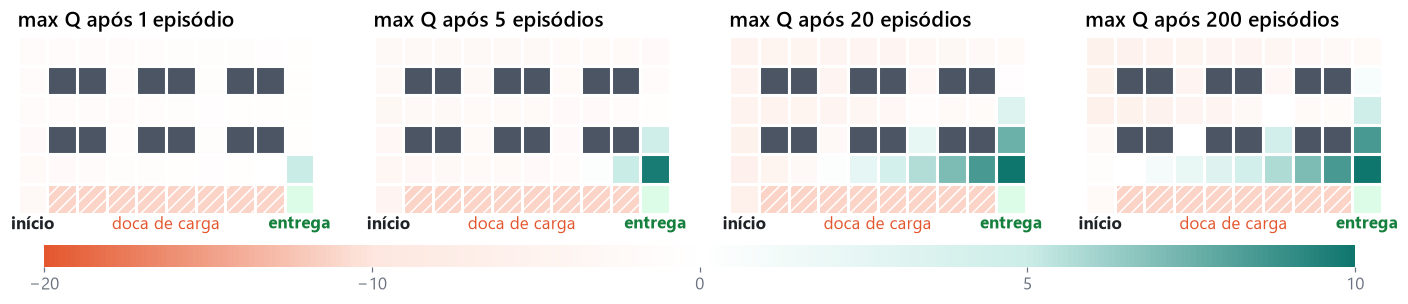

In [8]:
def escolher_eps_greedy(Q, s, eps, rng):
    """Com prob. eps escolhe ação aleatória; senão, a de maior Q (empates sorteados)."""
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))

def episodio_q_learning(env, Q, alpha, gamma, eps, rng, registrar=False):
    s = env.reset(); log = []
    while True:
        a = escolher_eps_greedy(Q, s, eps, rng)
        s2, r, term, trunc, _ = env.step(a)
        alvo = r if term else r + gamma * Q[s2].max()
        antes = Q[s, a]
        Q[s, a] += alpha * (alvo - Q[s, a])
        if registrar: log.append((env.posicao(s), NOMES_ACOES[a], r, antes, alvo, Q[s, a]))
        s = s2
        if term or trunc: return log

env = Armazem(seed=1); rng = np.random.default_rng(1)
Q = np.zeros((env.n_estados, 4)); fotos_q = {}
for ep in range(1, 201):
    log = episodio_q_learning(env, Q, alpha=0.5, gamma=0.95, eps=0.1, rng=rng, registrar=(ep == 1))
    if ep == 1:
        print("Primeiras 6 atualizações do episódio 1:")
        print(f"{'estado':>8} {'ação':>9} {'r':>5} {'Q antes':>8} {'alvo':>7} {'Q depois':>9}")
        for (p, a, r, qa, y, qd) in log[:6]:
            print(f"{str(p):>8} {a:>9} {r:>5.0f} {qa:>8.2f} {y:>7.2f} {qd:>9.2f}")
        print(f"... episódio 1 terminou após {len(log)} passos.\n")
    if ep in (1, 5, 20, 200):
        fotos_q[ep] = Q.max(1).copy()

fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, ep in zip(axs, fotos_q):
    desenhar_armazem(env, ax, valores=fotos_q[ep], escala=(-20, 10), barra=False,
                     titulo=f"max Q após {ep} " + ("episódio" if ep == 1 else "episódios"))
barra_compartilhada(fig, axs, -20, 10)
mostrar(fig, "p5_propagacao_td")

**Interpretação.**

* **Linha 1:** partindo do início, o robô tentou ir para a direita e caiu na doca. Alvo = −100, e $Q$ passa de 0 para −50 (anda metade do caminho, porque $\alpha = 0{,}5$).
* **Linhas 2 a 5:** cada par visitado pela primeira vez tem alvo $-1 + 0{,}95 \times \max_{a'} Q(s', a')$. Como o próximo estado ainda tem pelo menos uma ação valendo 0, o alvo é −1 e $Q$ cai para −0,5.
* **Linha 6:** primeira revisita de um par. Agora todas as ações do próximo estado já são negativas ($\max = -0{,}5$), então o alvo é $-1 + 0{,}95 \times (-0{,}5) = -1{,}48$ e $Q$ cai para −0,99. A informação começa a se acumular.
* Como as ações já testadas ficam negativas e as não testadas continuam em zero, a escolha gulosa prefere o que ainda não foi tentado. Inicializar com zero, num problema de recompensas negativas, funciona como um incentivo à exploração (Sutton; Barto, 2018, seção 2.6).
* Depois que o robô chega à entrega pela primeira vez, o +10 entra no alvo da última transição e, episódio após episódio, recua pelas células do caminho. É a mesma propagação da Parte 4, só que agora feita **por amostras**, sem conhecer o modelo.

## Parte 6 · SARSA vs. Q-Learning no armazém

Treinamos os dois algoritmos com **os mesmos hiperparâmetros e o mesmo orçamento**: 500 episódios, $\alpha = 0{,}1$, $\gamma = 0{,}99$, $\varepsilon = 0{,}1$ fixo, 20 sementes independentes.

A diferença entre os dois códigos está no **alvo** da atualização e, por consequência, no momento em que a próxima ação $a'$ é sorteada (antes da atualização no SARSA, depois no Q-Learning).

In [9]:
def treinar(env, metodo, episodios=500, alpha=0.1, gamma=0.99, eps=0.1, seed=0, n_planejamento=0):
    """metodo: 'sarsa' ou 'q'. n_planejamento > 0 ativa o Dyna-Q (Parte 8).
    eps pode ser um número fixo ou uma função do episódio (para decaimento)."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_estados, env.n_acoes))
    modelo = {}                     # Dyna-Q: modelo[(s, a)] = (r, s', terminal)
    acoes_vistas = {}               # Dyna-Q: estado -> ações já tomadas nele
    hist = {"retorno": [], "passos": [], "quedas": []}
    for ep in range(episodios):
        e = eps(ep) if callable(eps) else eps
        s = env.reset()
        a = escolher_eps_greedy(Q, s, e, rng)
        G, n, quedas = 0.0, 0, 0
        while True:
            s2, r, term, trunc, caiu = env.step(a)
            if metodo == "sarsa":
                a2 = escolher_eps_greedy(Q, s2, e, rng)       # SARSA: a' é escolhida ANTES da atualização
                alvo = r if term else r + gamma * Q[s2, a2]   # on-policy: valor da ação que será executada
            else:
                alvo = r if term else r + gamma * Q[s2].max() # off-policy: valor da melhor ação estimada
            Q[s, a] += alpha * (alvo - Q[s, a])

            if n_planejamento:                                # ---- Dyna-Q (Sutton; Barto, 2018, seção 8.2) ----
                modelo[(s, a)] = (r, s2, term)                # aprende o modelo (ambiente determinístico)
                acoes_vistas.setdefault(s, [])
                if a not in acoes_vistas[s]: acoes_vistas[s].append(a)
                estados = list(acoes_vistas.keys())
                for _ in range(n_planejamento):               # experiência simulada
                    ps = estados[rng.integers(len(estados))]  # estado já visitado
                    pa = acoes_vistas[ps][rng.integers(len(acoes_vistas[ps]))]  # ação já tomada nele
                    pr, ps2, pt = modelo[(ps, pa)]
                    palvo = pr if pt else pr + gamma * Q[ps2].max()
                    Q[ps, pa] += alpha * (palvo - Q[ps, pa])

            if metodo != "sarsa":
                a2 = escolher_eps_greedy(Q, s2, e, rng)       # Q-Learning/Dyna-Q: escolhe depois de atualizar
            G += r; n += 1; quedas += caiu
            s, a = s2, a2
            if term or trunc: break
        hist["retorno"].append(G); hist["passos"].append(n); hist["quedas"].append(quedas)
    return Q, {k: np.array(v) for k, v in hist.items()}

def rota_gulosa(env, Q, max_passos=60):
    """Segue argmax Q a partir do início usando o modelo sem ruído."""
    p, rota = env.inicio, [env.inicio]
    for _ in range(max_passos):
        p, _, term, _ = env.transicao(p, int(np.argmax(Q[env.indice(p)])))
        rota.append(p)
        if term: break
    return rota

SEMENTES = range(20)
t0 = time.time()
treinos = {m: [treinar(Armazem(seed=s), m, seed=s) for s in SEMENTES] for m in ["sarsa", "q"]}
print(f"tempo de treino: {time.time() - t0:.1f} s")

for m, nome in [("sarsa", "SARSA"), ("q", "Q-Learning")]:
    comp = [len(rota_gulosa(Armazem(), Q)) - 1 for Q, _ in treinos[m]]
    ret = np.array([h["retorno"][-100:].mean() for _, h in treinos[m]])
    qd = np.array([h["quedas"].sum() for _, h in treinos[m]])
    qd_final = np.array([h["quedas"][-100:].mean() for _, h in treinos[m]])
    print(f"{nome:>10}: rota final com {np.median(comp):.0f} passos (mediana) | "
          f"retorno médio (sem desconto) nos episódios 401 a 500 = {ret.mean():6.1f} | "
          f"quedas na doca nos 500 episódios = {qd.mean():.0f} por semente "
          f"({qd_final.mean():.2f} por episódio nos episódios 401 a 500)")

tempo de treino: 16.0 s
     SARSA: rota final com 15 passos (mediana) | retorno médio (sem desconto) nos episódios 401 a 500 =   -9.5 | quedas na doca nos 500 episódios = 53 por semente (0.04 por episódio nos episódios 401 a 500)
Q-Learning: rota final com 11 passos (mediana) | retorno médio (sem desconto) nos episódios 401 a 500 =  -30.2 | quedas na doca nos 500 episódios = 159 por semente (0.28 por episódio nos episódios 401 a 500)


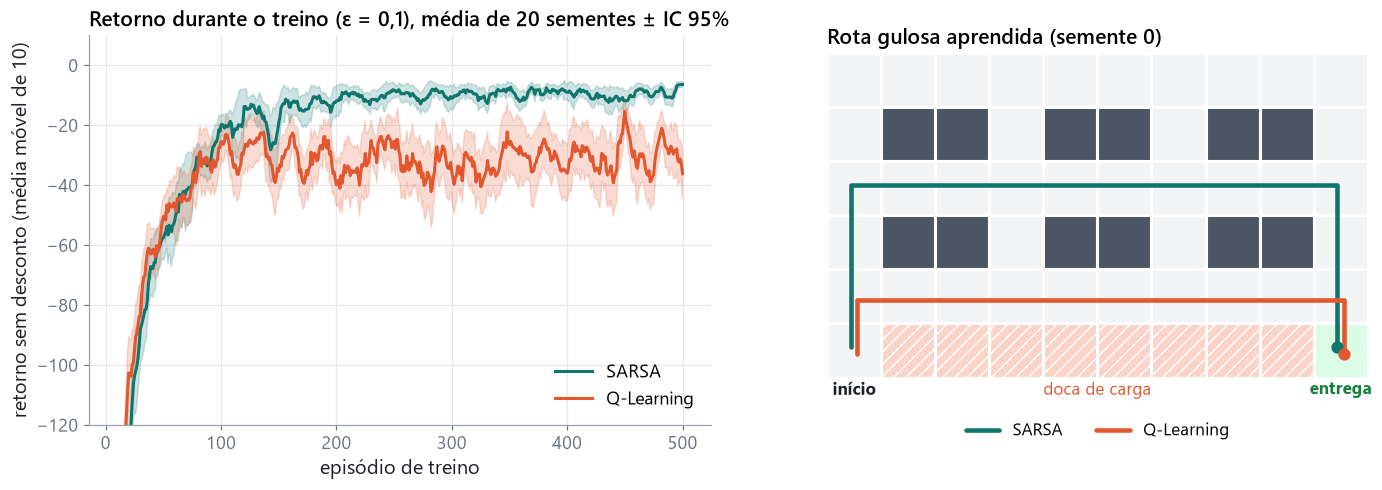

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
JAN = 10
for m, nome in [("sarsa", "SARSA"), ("q", "Q-Learning")]:
    curvas = np.array([media_movel(h["retorno"], JAN) for _, h in treinos[m]])
    media, ep = curvas.mean(0), curvas.std(0) / np.sqrt(len(curvas))
    x = np.arange(JAN, JAN + len(media))
    cor = COR["sarsa"] if m == "sarsa" else COR["qlearn"]
    axs[0].plot(x, media, color=cor, linewidth=2, label=nome)
    axs[0].fill_between(x, media - 1.96 * ep, media + 1.96 * ep, color=cor, alpha=0.2)
axs[0].set_ylim(-120, 10)
axs[0].set(xlabel="episódio de treino", ylabel=f"retorno sem desconto (média móvel de {JAN})")
axs[0].set_title("Retorno durante o treino (ε = 0,1), média de 20 sementes ± IC 95%", loc="left")
axs[0].legend(loc="lower right")

env = Armazem()
desenhar_armazem(env, axs[1], rotas=[(rota_gulosa(env, treinos["sarsa"][0][0]), COR["sarsa"], "SARSA"),
                                     (rota_gulosa(env, treinos["q"][0][0]), COR["qlearn"], "Q-Learning")],
                 titulo="Rota gulosa aprendida (semente 0)")
mostrar(fig, "p6_sarsa_vs_q")

**Interpretação.**

1. **Rotas (à direita).** O Q-Learning aprende a rota curta, colada à doca (11 passos), que é a política ótima do ambiente sem falhas. O SARSA aprende a rota afastada (15 passos).
2. **Retorno durante o treino (à esquerda, sem desconto).** Mesmo tendo aprendido a rota mais curta, o Q-Learning obtém **retorno menor** durante o treino e cai mais vezes na doca (números impressos acima).

**A conta do risco.** Com $\varepsilon = 0{,}1$, em cada passo ao lado da doca há $0{,}1 \times 1/4 = 2{,}5\%$ de chance de a ação aleatória ser "baixo". Na rota curta há 9 decisões arriscadas (no início, onde "direita" cai na doca, e nas 8 células logo acima dela): a chance de atravessar sem cair é $0{,}975^9 \approx 0{,}80$, ou seja, cerca de 20% de chance de queda a cada travessia. Cada queda custa −100 e recomeça o trajeto, que pode cair de novo. Na fase estável, o número esperado de quedas por episódio é $0{,}2/0{,}8 = 0{,}25$, o que bate com a taxa impressa para os episódios 401 a 500. Um quarto de queda por episódio custa, em média, 25 pontos, e isso explica a maior parte da diferença entre os retornos (−30 contra −9,5). As 159 quedas no total incluem também o início do treino, quando o robô ainda não conhece a rota.

**Causa.** O alvo do Q-Learning usa $\max_{a'} Q(s',a')$: ele avalia cada estado como se dali em diante fosse agir de forma gulosa, e por isso não leva em conta que ele mesmo ainda explora. O SARSA usa $Q(s',a')$ da ação que realmente sorteou, então as quedas causadas pela exploração entram nos valores. As células ao lado da doca ficam com valor baixo e o SARSA aprende a se afastar.

O Q-Learning estima o valor da política ótima ($Q^*$); o SARSA estima o valor da política que está sendo executada, com exploração incluída. É o mesmo fenômeno do exemplo *Cliff Walking* (Sutton; Barto, 2018, Exemplo 6.6).

**Atenção:** essa diferença existe porque $\varepsilon$ ficou **constante**. Se a exploração for reduzida gradualmente, satisfazendo a condição GLIE, o SARSA também passa a aprender a rota curta (Sutton; Barto, 2018, Exemplo 6.6; Singh et al., 2000). As próximas células testam isso, variando $\varepsilon$ e $\gamma$ como propõe o estudo de caso do material.

In [11]:
cenarios = [("ε = 0,01", 0.01, 0.99), ("ε = 0,05", 0.05, 0.99), ("ε = 0,1", 0.1, 0.99),
            ("ε = 0,2", 0.2, 0.99), ("ε = 0,1 e γ = 0,9", 0.1, 0.9)]
t0 = time.time()
print("Rota gulosa final (em passos), 10 sementes por cenário: 11 = rota curta, 15 = rota afastada")
print(f"{'cenário':<22}{'SARSA (mediana)':>17}{'SARSA rota curta':>19}{'Q-Learning (mediana)':>23}")
for nome, e, g in cenarios:
    comp = {m: [len(rota_gulosa(Armazem(), treinar(Armazem(seed=s), m, eps=e, gamma=g, seed=s)[0])) - 1
                for s in range(10)] for m in ["sarsa", "q"]}
    curtas = sum(c == 11 for c in comp["sarsa"])
    print(f"{nome:<22}{np.median(comp['sarsa']):>17.0f}{str(curtas) + ' de 10':>19}{np.median(comp['q']):>23.0f}")
print(f"tempo: {time.time() - t0:.1f} s")

Rota gulosa final (em passos), 10 sementes por cenário: 11 = rota curta, 15 = rota afastada
cenário                 SARSA (mediana)   SARSA rota curta   Q-Learning (mediana)


ε = 0,01                             11           10 de 10                     11


ε = 0,05                             15            0 de 10                     11


ε = 0,1                              15            0 de 10                     11


ε = 0,2                              15            0 de 10                     11


ε = 0,1 e γ = 0,9                    15            0 de 10                     11
tempo: 36.2 s


**Interpretação.** A rota do Q-Learning não depende de $\varepsilon$: ele sempre estima a política gulosa e aprende a rota curta em todos os cenários. A do SARSA depende: com $\varepsilon = 0{,}01$ a exploração quase nunca derruba o robô, o risco que entra nos valores é pequeno e o SARSA também escolhe a rota curta; a partir de $\varepsilon = 0{,}05$ ele passa a se afastar da doca. Reduzir $\gamma$ para 0,9 não muda a escolha de nenhum dos dois.

A teoria completa o quadro: se a exploração for reduzida aos poucos sem nunca parar de todo (condição GLIE), o SARSA converge para a política ótima, a mesma do Q-Learning (Singh et al., 2000; Sutton; Barto, 2018, Exemplo 6.6). A próxima célula mostra que isso depende de **como** a exploração diminui.

In [12]:
def decai_rapido(ep):
    """ε cai linearmente de 0,1 a zero até o episódio 400 (e fica em zero)."""
    return 0.1 * max(0.0, 1 - ep / 400)

def decai_lento(ep):
    """ε = 0,1 / (1 + ep/20): diminui sem nunca chegar a zero (estilo GLIE)."""
    return 0.1 / (1 + ep / 20)

t0 = time.time()
for nome, e, n_ep in [("ε decai rápido até 0 (500 episódios)", decai_rapido, 500),
                      ("ε decai lento, sem zerar (3.000 episódios)", decai_lento, 3000)]:
    comp = [len(rota_gulosa(Armazem(), treinar(Armazem(seed=s), "sarsa", episodios=n_ep, eps=e, seed=s)[0])) - 1
            for s in range(10)]
    print(f"SARSA, {nome:<42} rotas: {comp} | rota curta em {sum(c == 11 for c in comp)} de 10")
print(f"tempo: {time.time() - t0:.1f} s")

SARSA, ε decai rápido até 0 (500 episódios)       rotas: [15, 15, 15, 15, 15, 15, 15, 15, 15, 15] | rota curta em 0 de 10


SARSA, ε decai lento, sem zerar (3.000 episódios) rotas: [11, 11, 11, 15, 11, 15, 15, 11, 15, 11] | rota curta em 6 de 10
tempo: 17.9 s


**Interpretação.** Quando $\varepsilon$ chega a zero cedo, o SARSA para de visitar a borda da doca antes de reavaliá-la: os valores pessimistas daquela região ficam congelados e ele mantém a rota afastada. Com um decaimento lento, que nunca zera, ele continua passando de vez em quando pela borda; como a exploração vai ficando rara, o risco que entra nos valores diminui, e parte das sementes já converge para a rota curta em 3.000 episódios. A convergência garantida pela teoria (GLIE) é assintótica: na prática ela pode exigir muitos episódios.

Portanto, a diferença entre os dois algoritmos aparece **enquanto o agente explora**, e o que a decide é se o risco da exploração entra ou não no alvo da atualização.

## Parte 7 · Avaliar direito: protocolo, ruído e incerteza

O retorno de treino mistura aprendizado e exploração. Para comparar políticas, o protocolo da aula pede **episódios de avaliação separados, sem atualização de parâmetros**, com várias sementes e medidas de incerteza (Henderson et al., 2018; Agarwal et al., 2021).

Avaliamos as 20 políticas finais de cada algoritmo em dois cenários:

* **robô perfeito:** política gulosa, sem ruído;
* **robô com falhas:** 10% das ações saem aleatórias (falha de atuador), um caso de mudança entre treino e uso real.

Métricas: taxa de sucesso (entregar em até 100 passos), retorno, quedas na doca por episódio.

cenário                 algoritmo     sucesso        retorno médio [IC 95%]  quedas/ep
robô perfeito           SARSA         100.0%        -4.0  [  -4.0,   -4.0]       0.00
robô perfeito           Q-Learning    100.0%         0.0  [   0.0,    0.0]       0.00
robô com 10% de falhas  SARSA         100.0%        -9.6  [ -10.4,   -8.8]       0.04
robô com 10% de falhas  Q-Learning    100.0%       -31.8  [ -33.4,  -30.2]       0.29



Q-Learning treinado COM 10% de falhas: rota mediana = 15 passos | retorno de avaliação com falhas = -9.7


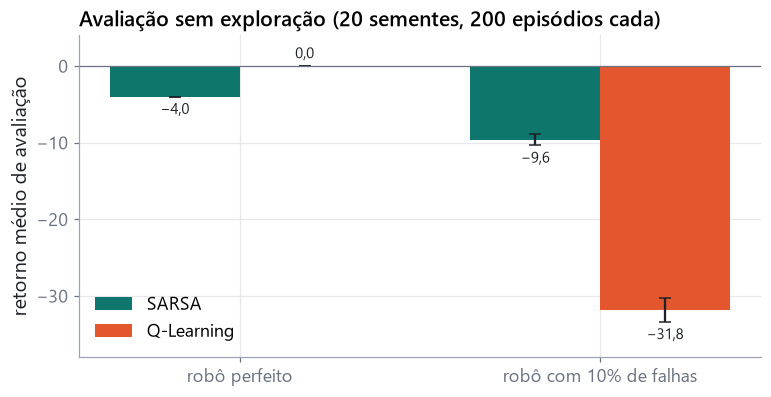

In [13]:
def avaliar(Q, ruido, n_episodios=200, seed=123, max_passos=100):
    env = Armazem(ruido=ruido, seed=seed, max_passos=max_passos)
    sucesso, retornos, quedas = [], [], []
    for _ in range(n_episodios):
        s = env.reset(); G = 0; nq = 0
        while True:
            s, r, term, trunc, caiu = env.step(int(np.argmax(Q[s])))   # sem exploração, sem aprendizado
            G += r; nq += caiu
            if term or trunc: break
        sucesso.append(term); retornos.append(G); quedas.append(nq)
    return np.mean(sucesso), np.mean(retornos), np.mean(quedas)

tabela = {}
for cenario, ruido in [("robô perfeito", 0.0), ("robô com 10% de falhas", 0.1)]:
    for m, nome in [("sarsa", "SARSA"), ("q", "Q-Learning")]:
        res = np.array([avaliar(Q, ruido, seed=100 + i) for i, (Q, _) in enumerate(treinos[m])])
        tabela[(cenario, nome)] = res

print(f"{'cenário':<24}{'algoritmo':<12}{'sucesso':>9}{'retorno médio [IC 95%]':>30}{'quedas/ep':>11}")
for (cenario, nome), res in tabela.items():
    m, lo, hi = ic95_bootstrap(res[:, 1])
    print(f"{cenario:<24}{nome:<12}{res[:, 0].mean():>8.1%}{m:>12.1f}  [{lo:6.1f}, {hi:6.1f}]{res[:, 2].mean():>11.2f}")

# Controle: e se o Q-Learning for TREINADO no robô com falhas?
ret_q_ruido = []
for s in range(10):
    Q_r, _ = treinar(Armazem(ruido=0.1, seed=s), "q", seed=s)
    ret_q_ruido.append((len(rota_gulosa(Armazem(), Q_r)) - 1, avaliar(Q_r, 0.1, seed=500 + s)[1]))
ret_q_ruido = np.array(ret_q_ruido)
print(f"\nQ-Learning treinado COM 10% de falhas: rota mediana = {np.median(ret_q_ruido[:, 0]):.0f} passos | "
      f"retorno de avaliação com falhas = {ret_q_ruido[:, 1].mean():.1f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
largura = 0.36
for k, (nome, cor) in enumerate([("SARSA", COR["sarsa"]), ("Q-Learning", COR["qlearn"])]):
    medias, erros = [], []
    for cenario in ["robô perfeito", "robô com 10% de falhas"]:
        m, lo, hi = ic95_bootstrap(tabela[(cenario, nome)][:, 1])
        medias.append(m); erros.append([[m - lo], [hi - m]])
    xs = np.arange(2) + (k - 0.5) * largura
    ax.bar(xs, medias, largura, color=cor, label=nome)
    ax.errorbar(xs, medias, yerr=np.hstack(erros), fmt="none", ecolor=COR["tinta"], capsize=4)
    for x, v, e in zip(xs, medias, erros):
        y_txt = v - e[0][0] - 0.8 if v < -0.5 else 0.6
        ax.text(x, y_txt, f"{v:.1f}".replace(".", ",").replace("-", "−"), ha="center", va="top" if v < -0.5 else "bottom",
                fontsize=10, color=COR["tinta"])
ax.axhline(0, color=COR["cinza"], linewidth=0.8)
ax.set_ylim(-38, 4)
ax.set_xticks(range(2), ["robô perfeito", "robô com 10% de falhas"])
ax.set_ylabel("retorno médio de avaliação")
ax.set_title("Avaliação sem exploração (20 sementes, 200 episódios cada)", loc="left")
ax.legend()
mostrar(fig, "p7_avaliacao")

**Interpretação.**

Os retornos aqui são **sem desconto**: 0 = 10 × (−1) + 10 na rota curta; −4 = 14 × (−1) + 10 na afastada.

* **Robô perfeito:** os dois chegam sempre. O Q-Learning tem retorno maior (0 contra −4), porque sua rota é 4 passos mais curta. Se o ambiente real for igual ao simulado, ele é a melhor escolha. Os intervalos têm largura zero porque as 20 sementes aprenderam a mesma rota e o ambiente é determinístico: não há variação nenhuma para medir.
* **Robô com falhas:** a situação se inverte. A política do Q-Learning anda colada à doca e cai com frequência; o retorno médio despenca. A rota do SARSA também piora (por causa dos desvios provocados pelo ruído), mas cai na doca muito menos. A taxa de sucesso fica em 100% para os dois porque, neste ambiente, cair na doca não encerra o episódio: o custo aparece no retorno. Olhar só a taxa de sucesso esconderia essa diferença.
* **Intervalos de confiança:** os colchetes são o IC de 95% da **média** das 20 sementes, por bootstrap. Aqui eles não se sobrepõem, então a diferença entre os algoritmos é clara para este experimento. Quando dois intervalos se sobrepõem muito, não dá para afirmar que um algoritmo é melhor que o outro (Henderson et al., 2018; Agarwal et al., 2021).

**Cuidado com a conclusão.** A vantagem do SARSA neste cenário é, em boa parte, construída pelo experimento: ele foi treinado com ε = 0,1 de ações aleatórias, que é estatisticamente o mesmo que o "robô com 10% de falhas". A última linha impressa mostra o controle: quando o próprio Q-Learning é **treinado** no ambiente com falhas, a política ótima desse ambiente já considera o risco, e ele também aprende a se afastar da doca. A lição não é "SARSA é melhor em ambientes ruidosos", e sim que o agente deve ser treinado e avaliado nas condições em que será usado. Esse é o ponto da discussão do estudo de caso de navegação em grade do material da disciplina.

## Parte 8 · Dyna-Q: planejar com um modelo aprendido

O Q-Learning usa cada transição real **uma vez** e a descarta. O Dyna-Q (Sutton, 1990; 1991) guarda o que viu num **modelo** `modelo[(s, a)] = (r, s', terminal)` e, a cada passo real, faz $n$ atualizações extras com transições **simuladas**: sorteia um estado já visitado, depois uma ação já tomada nele, e consulta o modelo, como no Dyna-Q tabular de Sutton e Barto (2018, seção 8.2).

O código já está na função `treinar` da Parte 6 (bloco `n_planejamento`). Comparamos $n = 0$ (Q-Learning puro), $n = 5$ e $n = 50$ medindo quantos passos cada episódio leva. O experimento segue a mesma ideia do Exemplo 8.1 de Sutton e Barto (2018). A mesma estrutura funciona com outras regras de atualização: o Exemplo 4 do professor aplica o planejamento ao SARSA (Dyna-SARSA).

tempo: 9.6 s


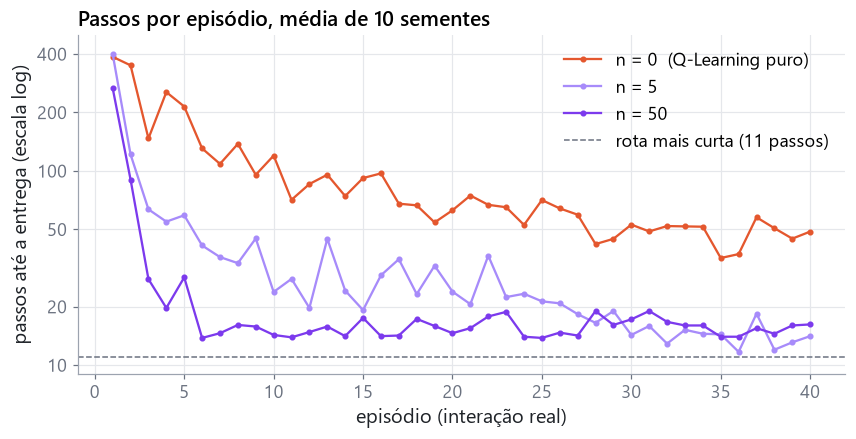

n =  0: passos no episódio 2 =  349.7 | média dos episódios 6 a 10 =  118.5 | total de passos reais em 40 episódios = 3784
n =  5: passos no episódio 2 =  121.5 | média dos episódios 6 a 10 =   35.9 | total de passos reais em 40 episódios = 1512
n = 50: passos no episódio 2 =   90.2 | média dos episódios 6 a 10 =   14.9 | total de passos reais em 40 episódios = 978


In [14]:
t0 = time.time()
dyna = {}
for n in [0, 5, 50]:
    dyna[n] = np.array([treinar(Armazem(seed=s), "q", episodios=40, seed=s, n_planejamento=n)[1]["passos"]
                        for s in range(10)])
print(f"tempo: {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(9, 4))
for n, cor in [(0, COR["qlearn"]), (5, "#A78BFA"), (50, COR["dyna"])]:
    ax.plot(np.arange(1, 41), dyna[n].mean(0), marker="o", markersize=3, color=cor,
            label=f"n = {n}" + ("  (Q-Learning puro)" if n == 0 else ""))
ax.axhline(11, color=COR["cinza"], linestyle="--", linewidth=1, label="rota mais curta (11 passos)")
ax.set_yscale("log"); ax.set_ylim(9, 500)
ax.set_yticks([10, 20, 50, 100, 200, 400], ["10", "20", "50", "100", "200", "400"]); ax.minorticks_off()
ax.set(xlabel="episódio (interação real)", ylabel="passos até a entrega (escala log)")
ax.set_title("Passos por episódio, média de 10 sementes", loc="left")
ax.legend()
mostrar(fig, "p8_dyna")

for n in [0, 5, 50]:
    print(f"n = {n:>2}: passos no episódio 2 = {dyna[n].mean(0)[1]:6.1f} | "
          f"média dos episódios 6 a 10 = {dyna[n].mean(0)[5:10].mean():6.1f} | "
          f"total de passos reais em 40 episódios = {dyna[n].sum(1).mean():.0f}")

**Interpretação.**

* No primeiro episódio, todos levam centenas de passos. O modelo começa a ser preenchido já no primeiro passo e o planejamento espalha os custos −1 e −100 conhecidos, mas ninguém sabe ainda onde está o +10: não há o que propagar a partir da entrega. (No Exemplo 8.1 de Sutton e Barto o primeiro episódio é idêntico para todos porque lá a recompensa é zero até a meta; aqui não é, por isso as três curvas diferem um pouco já no episódio 1.)
* A partir do segundo episódio, depois de achar a entrega uma vez, o agente com $n = 50$ propaga o +10 pelo modelo: cai para cerca de 90 passos no segundo episódio e para perto de 15 entre o sexto e o décimo. O Q-Learning puro ainda leva cerca de 350 passos no segundo episódio e cerca de 120 entre o sexto e o décimo. Em 40 episódios, o Q-Learning puro gastou cerca de 3.800 passos reais; o Dyna-Q com $n = 50$, menos de 1.000. Ele precisa de **muito menos interação real** para chegar a uma boa política: é a **eficiência amostral** citada no material.
* O custo foi transferido para a computação: com $n = 50$, cada passo real gera 51 atualizações. Isso vale a pena quando interagir com o mundo é caro (robôs físicos) e simular é barato.
* **Limite:** o modelo aqui é uma tabela de transições já vistas e supõe um ambiente determinístico. Se o ambiente mudar, o modelo fica desatualizado; os próprios Sutton e Barto discutem esse caso com o Dyna-Q+ (2018, seção 8.3).

## Parte 9 · Por que tabelas grandes são um problema

A tabela Q precisa de **uma entrada para cada par (estado, ação)**. Três problemas aparecem quando o número de estados cresce:

1. **Memória:** o tamanho cresce exponencialmente com o número de variáveis do estado. Bellman chamou isso de *maldição da dimensionalidade* (Bellman, 1957).
2. **Experiência:** cada entrada só melhora quando aquele par é visitado. Tabela grande com o mesmo orçamento de interações significa entradas que nunca foram atualizadas.
3. **Sem generalização:** a tabela não sabe que dois estados quase iguais devem ter valores parecidos. Aprender num estado não ajuda o vizinho.

Primeiro, o tamanho da tabela em alguns problemas.

In [15]:
exemplos = [
    ("Armazém deste notebook (linhas da tabela)",   np.log10(60)),
    ("CartPole: 4 variáveis, 10 faixas cada",       np.log10(10 ** 4)),
    ("CartPole: 4 variáveis, 100 faixas cada",      np.log10(100 ** 4)),
    ("Xadrez: posições (estimativa de Shannon)",    43.0),
    ("Go 19x19: posições legais (Tromp)",           np.log10(2.08) + 170),
    ("Atari: imagens 84x84 possíveis, 256 tons",    84 * 84 * np.log10(256)),
]
print("Número de estados (a tabela Q tem esse número vezes o número de ações)")
print(f"{'problema':<46}{'estados':>30}")
for nome, lg in exemplos:
    print(f"{nome:<46}{'~ 10^' + format(lg, '.1f'):>30}")

mem_10 = 10 ** 4 * 2 * 4 / 1e3
mem_100 = 100 ** 4 * 2 * 4 / 1e9
print(f"\nMemória com float32: CartPole 10 faixas = {mem_10:.0f} kB | CartPole 100 faixas = {mem_100:.1f} GB")

Número de estados (a tabela Q tem esse número vezes o número de ações)
problema                                                             estados
Armazém deste notebook (linhas da tabela)                           ~ 10^1.8
CartPole: 4 variáveis, 10 faixas cada                               ~ 10^4.0
CartPole: 4 variáveis, 100 faixas cada                              ~ 10^8.0
Xadrez: posições (estimativa de Shannon)                           ~ 10^43.0
Go 19x19: posições legais (Tromp)                                 ~ 10^170.3
Atari: imagens 84x84 possíveis, 256 tons                        ~ 10^16992.5

Memória com float32: CartPole 10 faixas = 80 kB | CartPole 100 faixas = 0.8 GB


Os números de xadrez (cerca de $10^{43}$ posições) vêm de Shannon (1950); o de Go ($2{,}08 \times 10^{170}$ posições legais) de Tromp (2016). O quadro 84 × 84 em tons de cinza é o pré-processamento usado pela DQN (Mnih et al., 2015), que ainda empilha 4 quadros: só um quadro já tem $256^{7056}$ imagens possíveis, um número com quase 17 mil dígitos. Nem todas são telas que o jogo realmente produz, mas a tabela não tem como saber quais são.

Agora o experimento que responde à pergunta na prática. Pegamos o **CartPole** (equilibrar um bastão sobre um carrinho, com 4 variáveis contínuas: posição, velocidade, ângulo e velocidade angular), dividimos cada variável em $k$ faixas e aplicamos **Q-Learning tabular**. Todos recebem o mesmo orçamento de **50 mil interações** com o ambiente (o mesmo da DQN na Parte 10), seguindo o protocolo da aula: orçamento igual em interações, não em episódios. São 5 sementes por tamanho de tabela.

A dinâmica do CartPole é definida na próxima célula e reutilizada na Parte 10.

In [16]:
class CartPole:
    """Dinâmica idêntica ao CartPole-v1 do Gymnasium (Barto; Sutton; Anderson, 1983).
    Estado: [posição, velocidade, ângulo, velocidade angular]. Ações: 0 = empurra p/ esquerda, 1 = direita.
    Recompensa +1 por passo. Termina se |ângulo| > 12° ou |posição| > 2,4; trunca em 500 passos."""
    g, m_carro, m_haste, meia_haste, forca, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    lim_angulo, lim_x = 12 * 2 * np.pi / 360, 2.4

    def __init__(self, seed=None, max_passos=500):
        self.rng = np.random.default_rng(seed); self.max_passos = max_passos

    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, 4); self.t = 0
        return self.s.copy()

    def step(self, a):
        x, x_v, th, th_v = self.s
        f = self.forca if a == 1 else -self.forca
        cos, sin = np.cos(th), np.sin(th)
        m_total = self.m_carro + self.m_haste
        temp = (f + self.m_haste * self.meia_haste * th_v ** 2 * sin) / m_total
        th_a = (self.g * sin - cos * temp) / (self.meia_haste * (4 / 3 - self.m_haste * cos ** 2 / m_total))
        x_a = temp - self.m_haste * self.meia_haste * th_a * cos / m_total
        x, x_v = x + self.tau * x_v, x_v + self.tau * x_a          # integração de Euler
        th, th_v = th + self.tau * th_v, th_v + self.tau * th_a
        self.s = np.array([x, x_v, th, th_v]); self.t += 1
        terminal = bool(abs(x) > self.lim_x or abs(th) > self.lim_angulo)
        return self.s.copy(), 1.0, terminal, self.t >= self.max_passos


def discretizar(s, k, limites=np.array([2.4, 3.0, 0.21, 3.5])):
    """Converte o estado contínuo em uma tupla de índices (uma faixa por variável)."""
    z = np.clip((s + limites) / (2 * limites), 0, 0.999999)
    return tuple((z * k).astype(int))

def q_learning_discreto(k, passos_totais=50_000, seed=0):
    rng = np.random.default_rng(seed); env = CartPole(seed)
    Q = np.zeros((k,) * 4 + (2,)); visitado = np.zeros((k,) * 4, bool)
    passos = 0
    while passos < passos_totais:
        s = discretizar(env.reset(), k)
        while True:
            eps = max(0.01, 1 - passos / (passos_totais / 3))   # ε decai de 1 a 0,01 no primeiro terço do orçamento
            visitado[s] = True
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(Q[s]))
            s2c, r, term, trunc = env.step(a); s2 = discretizar(s2c, k); passos += 1
            Q[s + (a,)] += 0.1 * (r + (0 if term else 0.99 * Q[s2].max()) - Q[s + (a,)])
            s = s2
            if term or trunc: break
    # avaliação gulosa, sem aprendizado
    aval = []
    for _ in range(20):
        s, G = discretizar(env.reset(), k), 0
        while True:
            s2c, r, term, trunc = env.step(int(np.argmax(Q[s]))); G += r; s = discretizar(s2c, k)
            if term or trunc: break
        aval.append(G)
    return np.mean(aval), visitado.mean()

t0 = time.time()
FAIXAS = [1, 3, 6, 10, 20]
res_faixas = {k: np.array([q_learning_discreto(k, seed=s) for s in range(5)]) for k in FAIXAS}
print(f"tempo: {time.time() - t0:.1f} s\n")
print("Retorno de avaliação: média ± desvio padrão entre 5 sementes")
print(f"{'faixas':>7}{'entradas na tabela':>20}{'retorno de avaliação':>23}{'% dos estados visitados':>26}")
for k in FAIXAS:
    r = res_faixas[k]
    print(f"{k:>7}{2 * k ** 4:>20,}{r[:, 0].mean():>16.0f} ± {r[:, 0].std(ddof=1):<5.0f}{r[:, 1].mean():>23.1%}")

tempo: 50.5 s

Retorno de avaliação: média ± desvio padrão entre 5 sementes
 faixas  entradas na tabela   retorno de avaliação   % dos estados visitados
      1                   2               9 ± 0                     100.0%
      3                 162              77 ± 4                      44.4%
      6               2,592             142 ± 33                     12.1%
     10              20,000              87 ± 16                      4.6%
     20             320,000              68 ± 16                      0.8%


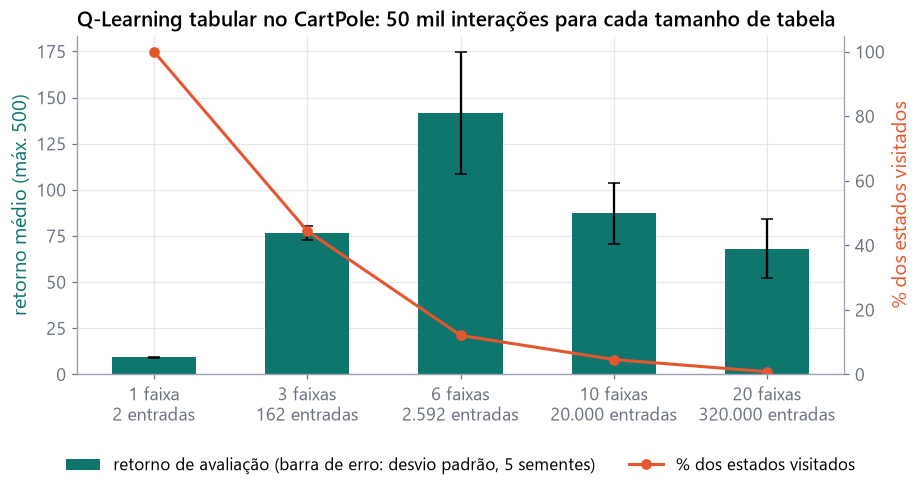

In [17]:
fig, ax1 = plt.subplots(figsize=(9, 4))
xs = np.arange(len(FAIXAS))
med = [res_faixas[k][:, 0].mean() for k in FAIXAS]; dp = [res_faixas[k][:, 0].std(ddof=1) for k in FAIXAS]
ax1.bar(xs, med, 0.55, yerr=dp, capsize=4, color=COR["sarsa"], label="retorno de avaliação (barra de erro: desvio padrão, 5 sementes)")
ax1.set_xticks(xs, [(f"{k} faixa" if k == 1 else f"{k} faixas") + f"\n{2 * k ** 4:,} entradas".replace(",", ".") for k in FAIXAS])
ax1.set_ylabel("retorno médio (máx. 500)", color=COR["sarsa"])
ax2 = ax1.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax2.plot(xs, [res_faixas[k][:, 1].mean() * 100 for k in FAIXAS], color=COR["qlearn"], marker="o", linewidth=2, label="% dos estados visitados")
ax2.set_ylabel("% dos estados visitados", color=COR["qlearn"]); ax2.set_ylim(0, 105)
ax1.set_title("Q-Learning tabular no CartPole: 50 mil interações para cada tamanho de tabela", loc="left")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=11)
mostrar(fig, "p9_faixas")

**Interpretação.** O desempenho sobe e depois cai.

* **1 faixa:** todos os estados viram um só. O agente não distingue "bastão caindo para a esquerda" de "caindo para a direita" e não consegue equilibrar (cerca de 9 passos).
* **Resoluções intermediárias:** a tabela distingue situações relevantes e o desempenho melhora bastante; o melhor resultado médio foi com 6 faixas (cerca de 140 passos). O número exato do pico depende do orçamento e das sementes; o que se repete é o formato de "sobe e desce".
* **20 faixas:** 320 mil entradas. Com o mesmo orçamento, **só uma fração pequena dos estados foi visitada** (linha laranja; parte das faixas nem é alcançável, porque o episódio termina antes). Na avaliação, o agente cai em estados que nunca viu. Lá, as duas ações têm $Q = 0$, `np.argmax` devolve sempre a ação 0 (empurrar para a esquerda) e o bastão cai. O desempenho volta a cair.

Aumentar a resolução da tabela aumenta a precisão **possível**, mas exige experiência proporcional ao número de entradas, porque cada célula aprende sozinha. Uma **função aproximadora** (por exemplo, uma rede neural) resolve o terceiro problema: estados parecidos produzem saídas parecidas, então aprender num estado melhora os vizinhos. Esse é o passo da Parte 10.

## Parte 10 · DQN implementada em NumPy

A DQN (Mnih et al., 2013; 2015) troca a tabela por uma rede neural $Q_\theta(s,a)$: entra o estado (4 números contínuos, sem discretizar), saem 2 valores, um por ação.

Treinar com o alvo de Bellman de forma ingênua é instável. A DQN usa dois mecanismos:

| Mecanismo | Problema que resolve |
|---|---|
| **Replay buffer** (memória de transições, Lin, 1992) | passos consecutivos são muito correlacionados; amostrar mini-lotes aleatórios da memória quebra essa correlação e reutiliza cada experiência várias vezes |
| **Rede-alvo** $\theta^-$ (cópia congelada da rede) | o alvo $y = r + \gamma \max_{a'} Q_{\theta^-}(s',a')$ deixa de se mover a cada atualização; a cópia é sincronizada a cada $C$ passos |

O artigo da Nature limita o termo de erro $y - Q_\theta(s,a)$ ao intervalo $[-1, 1]$, o que equivale a usar a perda de Huber; fazemos o mesmo. Implementamos a rede (2 camadas ocultas de 64 neurônios, ReLU) e o otimizador Adam (Kingma; Ba, 2015) à mão, para que nada fique escondido em biblioteca.

In [18]:
class RedeMLP:
    """Rede totalmente conectada com ReLU, treinada com Adam. Escrita em NumPy para fins didáticos."""

    def __init__(self, camadas, rng, lr=1e-3):
        self.W = [rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(camadas[:-1], camadas[1:])]
        self.b = [np.zeros(b) for b in camadas[1:]]
        self.lr, self.passo = lr, 0
        self.m = [np.zeros_like(p) for p in self.W + self.b]
        self.v = [np.zeros_like(p) for p in self.W + self.b]

    def __call__(self, x, guardar=False):
        ativ = [x]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            x = x @ W + b
            if i < len(self.W) - 1:
                x = np.maximum(x, 0)                       # ReLU nas camadas ocultas
            ativ.append(x)
        if guardar: self.ativ = ativ
        return x                                           # saída linear: valores Q

    def retropropagar(self, grad_saida):
        grads_W, grads_b, g = [], [], grad_saida
        for i in reversed(range(len(self.W))):
            grads_W.insert(0, self.ativ[i].T @ g); grads_b.insert(0, g.sum(0))
            if i > 0:
                g = (g @ self.W[i].T) * (self.ativ[i] > 0)
        self.passo += 1; b1, b2 = 0.9, 0.999               # Adam
        for j, (p, gr) in enumerate(zip(self.W + self.b, grads_W + grads_b)):
            self.m[j] = b1 * self.m[j] + (1 - b1) * gr
            self.v[j] = b2 * self.v[j] + (1 - b2) * gr ** 2
            p -= self.lr * (self.m[j] / (1 - b1 ** self.passo)) / (np.sqrt(self.v[j] / (1 - b2 ** self.passo)) + 1e-8)

    def copiar_de(self, outra):
        self.W = [w.copy() for w in outra.W]; self.b = [b.copy() for b in outra.b]


ESCALA = np.array([2.4, 3.0, 0.21, 3.0])                    # normaliza as 4 variáveis para ~[-1, 1]

def politica_gulosa_retorno(rede, seed, n=5):
    env = CartPole(seed); total = []
    for _ in range(n):
        s, G = env.reset() / ESCALA, 0
        while True:
            s, r, term, trunc = env.step(int(np.argmax(rede(s[None])[0]))); s = s / ESCALA; G += r
            if term or trunc: break
        total.append(G)
    return np.mean(total)

def treinar_dqn(seed=0, passos_totais=50_000, gamma=0.99, lote=64, memoria=50_000, C=500,
                eps_decai=8_000, inicio_treino=1_000, avaliar_cada=10):
    rng = np.random.default_rng(seed); env = CartPole(seed)
    q = RedeMLP([4, 64, 64, 2], rng)                       # rede online (θ)
    q_alvo = RedeMLP([4, 64, 64, 2], rng); q_alvo.copiar_de(q)   # rede-alvo (θ⁻)
    # replay buffer em vetores circulares
    S, A, R = np.zeros((memoria, 4)), np.zeros(memoria, int), np.zeros(memoria)
    S2, D = np.zeros((memoria, 4)), np.zeros(memoria)
    n, passos, hist, aval = 0, 0, [], []
    while passos < passos_totais:
        s, G = env.reset() / ESCALA, 0
        while True:
            eps = max(0.02, 1 - 0.98 * passos / eps_decai)              # ε decai de 1 para 0,02
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(q(s[None])[0]))
            s2, r, term, trunc = env.step(a); s2 = s2 / ESCALA
            i = n % memoria
            S[i], A[i], R[i], S2[i], D[i] = s, a, r, s2, float(term)   # truncamento NÃO é terminal
            n += 1; passos += 1; G += r
            if n >= inicio_treino:
                idx = rng.integers(0, min(n, memoria), lote)            # mini-lote aleatório
                y = R[idx] + gamma * (1 - D[idx]) * q_alvo(S2[idx]).max(1)   # alvo com θ⁻
                q_pred = q(S[idx], guardar=True)
                erro = q_pred[np.arange(lote), A[idx]] - y
                grad = np.zeros_like(q_pred)
                grad[np.arange(lote), A[idx]] = np.clip(erro, -1, 1) / lote  # gradiente da perda de Huber
                q.retropropagar(grad)
                if passos % C == 0:
                    q_alvo.copiar_de(q)                                  # sincroniza a rede-alvo
            s = s2
            if term or trunc: break
        hist.append((passos, G))
        if len(hist) % avaliar_cada == 0:
            aval.append((passos, politica_gulosa_retorno(q, seed=10_000 + len(hist))))
    return q, np.array(hist), np.array(aval)

# referência: política aleatória
env = CartPole(seed=0); ret_aleatorio = []
rng = np.random.default_rng(0)
for _ in range(100):
    env.reset(); G = 0
    while True:
        _, r, term, trunc = env.step(int(rng.integers(2))); G += r
        if term or trunc: break
    ret_aleatorio.append(G)
print(f"Política aleatória: {np.mean(ret_aleatorio):.1f} passos em média")

t0 = time.time()
rede_dqn, hist_dqn, aval_dqn = treinar_dqn(seed=0)
print(f"DQN treinada em {time.time() - t0:.0f} s | {len(hist_dqn)} episódios | "
      f"melhor avaliação gulosa = {aval_dqn[:, 1].max():.0f} | última = {aval_dqn[-1, 1]:.0f}")

Política aleatória: 21.6 passos em média


DQN treinada em 35 s | 369 episódios | melhor avaliação gulosa = 500 | última = 177


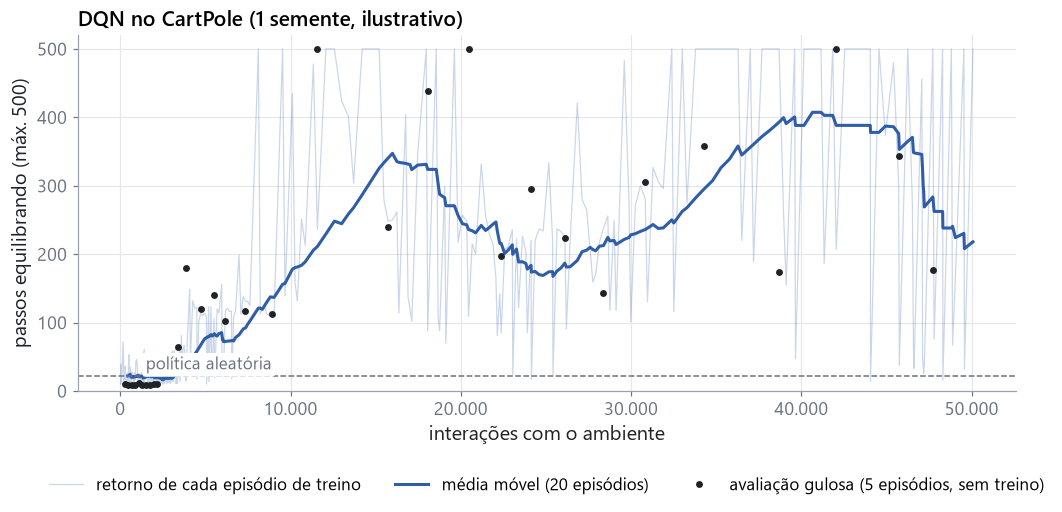

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(hist_dqn[:, 0], hist_dqn[:, 1], color=COR["dqn"], alpha=0.25, linewidth=0.8, label="retorno de cada episódio de treino")
ax.plot(hist_dqn[19:, 0], media_movel(hist_dqn[:, 1], 20), color=COR["dqn"], linewidth=2, label="média móvel (20 episódios)")
ax.plot(aval_dqn[:, 0], aval_dqn[:, 1], "o", color=COR["tinta"], markersize=3.5, label="avaliação gulosa (5 episódios, sem treino)")
ax.axhline(np.mean(ret_aleatorio), color=COR["cinza"], linestyle="--", linewidth=1)
ax.text(1500, np.mean(ret_aleatorio) + 10, "política aleatória", ha="left", color=COR["cinza"], fontsize=11,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none"))
ax.set(xlabel="interações com o ambiente", ylabel="passos equilibrando (máx. 500)", ylim=(0, 520))
ax.set_title("DQN no CartPole (1 semente, ilustrativo)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=11)
mostrar(fig, "p10_dqn")

**Interpretação.**

* No início, com $\varepsilon \approx 1$, o agente age ao acaso e equilibra o bastão por cerca de 20 passos, como a política aleatória.
* Conforme $\varepsilon$ decai e a rede aprende, os episódios ficam longos; a avaliação gulosa chega a centenas de passos e pode atingir o limite de 500.
* **A curva não é monotônica.** Há quedas bruscas mesmo depois de bons resultados. Isso é esperado: a rede é atualizada com alvos que dependem dela mesma, e uma atualização pode piorar valores de estados que já estavam bons. O material da disciplina cita essa instabilidade e a sensibilidade a hiperparâmetros como limitações da DQN. Sutton e Barto (2018, seção 11.3) chamam a combinação de aproximação de função, *bootstrapping* e aprendizado *off-policy* de "tríade mortal" (*deadly triad*).
* É por isso que se avalia a política periodicamente e separado do treino (pontos pretos). As extensões da DQN atacam partes do problema; a Double DQN (van Hasselt; Guez; Silver, 2016), por exemplo, reduz a superestimação dos valores causada pelo $\max$ no alvo.
* A curva de treino (azul) inclui exploração com $\varepsilon = 0{,}02$; os pontos pretos não. Por isso os dois números podem diferir.

**Se o seu número for diferente do slide:** a DQN é sensível a diferenças mínimas de ponto flutuante, então outra máquina ou outra versão do NumPy pode produzir outra curva com a mesma semente (num teste, a última avaliação deu 419 em vez de 177). Isso não é erro: é a mesma instabilidade descrita acima.

**Experimente:** troque `seed=0` por outras sementes. As curvas mudam bastante; esta é **uma única execução, ilustrativa**, e comparações sérias exigem várias sementes.

## Parte 11 · Outra família: gradiente de política (REINFORCE)

SARSA, Q-Learning e DQN aprendem **valores** e derivam a ação com $\arg\max$. Os métodos de **gradiente de política** fazem diferente: parametrizam diretamente a política $\pi_\theta(a \mid s)$ e ajustam $\theta$ para aumentar a probabilidade das ações que levaram a retornos altos (Williams, 1992):

$$\theta \leftarrow \theta + \alpha \, G_t \, \nabla_\theta \log \pi_\theta(A_t \mid S_t)$$

Aqui a política é uma **softmax linear**: $\pi_\theta(a \mid s) \propto \exp(s^\top \theta_a)$, com apenas 8 parâmetros. Não existe tabela nem valor Q. O orçamento é o mesmo da DQN: 50 mil interações com o ambiente.

Duas simplificações em relação à forma do livro (Sutton; Barto, 2018, seções 13.3 e 13.4), ambas comuns na prática: (1) os retornos de cada episódio são **normalizados** (subtrai-se a média e divide-se pelo desvio padrão), uma heurística comum que reduz a variância (lembra uma linha de base, mas não é uma linha de base no sentido estrito do livro, porque a média depende das ações do próprio episódio); (2) o fator $\gamma^t$ que multiplica cada termo na versão do livro é omitido.

REINFORCE, 5 sementes em 25 s | média dos últimos 20 episódios: 417 ± 31 (desvio padrão entre sementes) | semente 0: 460
DQN (1 semente, Parte 10), mesmo orçamento: média dos últimos 20 episódios de treino = 218

Preferência por 'direita' aprendida, θ[:, direita] − θ[:, esquerda] (semente 0):
  posição             +1.79
  velocidade          -1.17
  ângulo              +4.28
  velocidade angular  +3.75


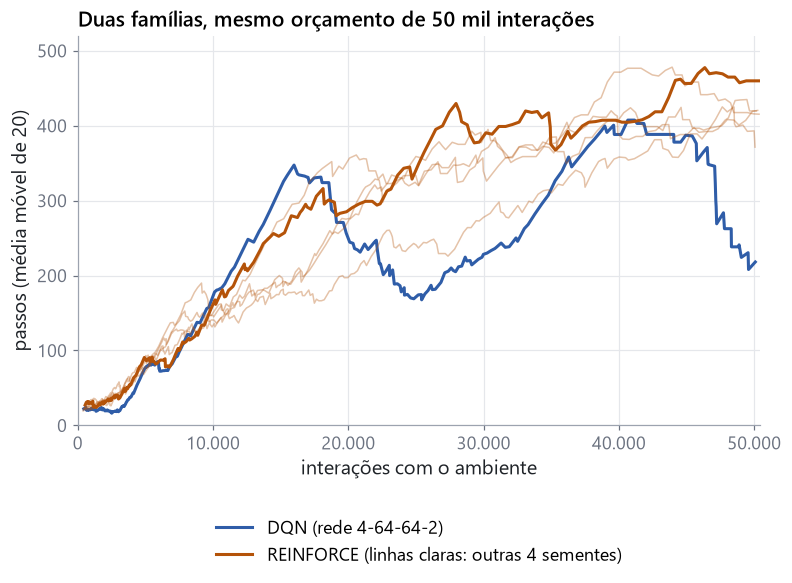

In [20]:
def treinar_reinforce(seed=0, passos_totais=50_000, lr=0.01, gamma=0.99):
    """Mesmo orçamento de interações da DQN da Parte 10."""
    rng = np.random.default_rng(seed); env = CartPole(seed)
    theta = np.zeros((4, 2)); hist, passos = [], 0
    while passos < passos_totais:
        s = env.reset() / ESCALA; estados, acoes, recompensas = [], [], []
        while True:                                    # 1) gera um episódio completo com π_θ
            z = s @ theta; p = np.exp(z - z.max()); p /= p.sum()
            a = rng.choice(2, p=p)
            s2, r, term, trunc = env.step(a)
            estados.append(s); acoes.append(a); recompensas.append(r)
            s = s2 / ESCALA
            if term or trunc: break
        G = np.zeros(len(recompensas)); acum = 0.0     # 2) retorno de cada passo
        for t in reversed(range(len(recompensas))):
            acum = recompensas[t] + gamma * acum; G[t] = acum
        G = (G - G.mean()) / (G.std() + 1e-8)          # normalização (reduz variância)
        for s_t, a_t, g_t in zip(estados, acoes, G):   # 3) sobe o gradiente de log π
            z = s_t @ theta; p = np.exp(z - z.max()); p /= p.sum()
            grad_log = -np.outer(s_t, p); grad_log[:, a_t] += s_t
            theta += lr * g_t * grad_log
        passos += len(recompensas); hist.append((passos, len(recompensas)))
    return theta, np.array(hist)

t0 = time.time()
execucoes = [treinar_reinforce(seed=s) for s in range(5)]          # 5 sementes, ~3 s cada
theta, hist_reinf = execucoes[0]
finais = np.array([h[-20:, 1].mean() for _, h in execucoes])
print(f"REINFORCE, 5 sementes em {time.time() - t0:.0f} s | média dos últimos 20 episódios: "
      f"{finais.mean():.0f} ± {finais.std(ddof=1):.0f} (desvio padrão entre sementes) | semente 0: {finais[0]:.0f}")
print(f"DQN (1 semente, Parte 10), mesmo orçamento: média dos últimos 20 episódios de treino = {hist_dqn[-20:, 1].mean():.0f}")
print("\nPreferência por 'direita' aprendida, θ[:, direita] − θ[:, esquerda] (semente 0):")
for nome, v in zip(["posição", "velocidade", "ângulo", "velocidade angular"], theta[:, 1] - theta[:, 0]):
    print(f"  {nome:<20}{v:+.2f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(hist_dqn[19:, 0], media_movel(hist_dqn[:, 1], 20), color=COR["dqn"], linewidth=2, label="DQN (rede 4-64-64-2)")
for _, h in execucoes[1:]:
    ax.plot(h[19:, 0], media_movel(h[:, 1], 20), color=COR["reinf"], linewidth=1, alpha=0.35)
ax.plot(hist_reinf[19:, 0], media_movel(hist_reinf[:, 1], 20), color=COR["reinf"], linewidth=2, label="REINFORCE (linhas claras: outras 4 sementes)")
ax.set(xlabel="interações com o ambiente", ylabel="passos (média móvel de 20)", ylim=(0, 520))
ax.set_xlim(0, max(hist_dqn[-1, 0], hist_reinf[-1, 0]))
ax.set_title("Duas famílias, mesmo orçamento de 50 mil interações", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=12)
mostrar(fig, "p11_reinforce_vs_dqn")

**Interpretação.**

* O REINFORCE aprende uma política estocástica diretamente, sem estimar $Q$. Com duas ações, o que decide a escolha é a diferença $\theta_{\text{direita}} - \theta_{\text{esquerda}}$ impressa acima: quanto maior $s^\top(\theta_{\text{direita}} - \theta_{\text{esquerda}})$, maior a chance de empurrar para a direita. Os pesos de **ângulo** e **velocidade angular** são positivos e são os maiores: se o bastão inclina ou gira para a direita, a política empurra o carrinho para a direita, para ficar embaixo dele. Os pesos de posição e velocidade do carrinho são menores e não dá para interpretá-los sozinhos: eles corrigem a deriva do carrinho em combinação com os outros dois.
* Neste problema, que é simples e tem uma boa solução linear, o REINFORCE terminou com cerca de 420 passos em média nas 5 sementes (desvio padrão de cerca de 30), enquanto a DQN da Parte 10, numa única semente e com o mesmo orçamento, terminou em torno de 220 nos episódios de treino (valores da execução salva; em outra máquina eles podem variar um pouco, como explicado na Parte 10). Isso **não** significa que ele seja melhor em geral: o REINFORCE puro tem variância alta e precisa de episódios completos para atualizar. Em problemas maiores, combina-se política e valor, os métodos **ator-crítico** (A2C, PPO, SAC; Mnih et al., 2016; Schulman et al., 2017; Haarnoja et al., 2018), citados na tabela de famílias do material.
* O eixo horizontal está em **interações com o ambiente**, não em episódios. Comparar algoritmos por episódio favorece quem tem episódios curtos; o protocolo da aula pede orçamento de interações igual.

## Parte 12 · Desenho de recompensa e *reward hacking*

Num corredor simplificado do armazém, sem doca, o projetista quer que o robô **chegue rápido** à entrega. Comparamos três formas de recompensa:

| Versão | Recompensa | Observação |
|---|---|---|
| **real** | −1 por passo, +10 na entrega | expressa o objetivo |
| **proxy ingênuo** | **substitui** a real: +1 sempre que o passo aproxima o robô da entrega, 0 caso contrário, +10 extra na entrega | parece razoável: "premiar progresso" |
| **shaping por potencial** | real + $\gamma\,\Phi(s') - \Phi(s)$, com $\Phi(s) = -\text{distância}(s, \text{entrega})$ | forma proposta por Ng, Harada e Russell (1999), que **não altera** a política ótima |

O proxy ingênuo não penaliza afastar-se. Um caso real desse defeito: um agente premiado por se aproximar do destino aprendeu a andar de bicicleta em círculos (Randløv; Alstrøm, 1998).

In [21]:
MAPA_ABERTO = [
    "........",
    ".##..##.",
    "........",
    ".##..##.",
    "S......G",
]

class ArmazemRecompensa(Armazem):
    def __init__(self, versao, **kw):
        super().__init__(MAPA_ABERTO, **kw); self.versao = versao
    def dist(self, p):
        return abs(p[0] - self.meta[0]) + abs(p[1] - self.meta[1])
    def transicao(self, p, a):
        p2, r, term, caiu = super().transicao(p, a)
        if self.versao == "proxy":
            r = (10.0 if term else 0.0) + (1.0 if self.dist(p2) < self.dist(p) else 0.0)
        elif self.versao == "potencial":
            phi, phi2 = -self.dist(p), (0.0 if term else -self.dist(p2))   # Φ(terminal) = 0
            r = r + 0.99 * phi2 - phi
        return p2, r, term, caiu

rotas_rec = {}
for versao in ["real", "proxy", "potencial"]:
    env_r = ArmazemRecompensa(versao, seed=0, max_passos=200)
    Q, _ = treinar(env_r, "q", episodios=3000, alpha=0.2, gamma=0.99, eps=0.1, seed=0)
    rota = rota_gulosa(env_r, Q, max_passos=30)
    rotas_rec[versao] = rota
    chegou = rota[-1] == env_r.meta
    print(f"{versao:>10}: {'entrega em ' + str(len(rota) - 1) + ' passos' if chegou else 'NÃO entrega em 30 passos'}"
          f" | início da rota: {rota[:9]}")

      real: entrega em 7 passos | início da rota: [(4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7)]


     proxy: NÃO entrega em 30 passos | início da rota: [(4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 5), (4, 6)]


 potencial: entrega em 7 passos | início da rota: [(4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7)]


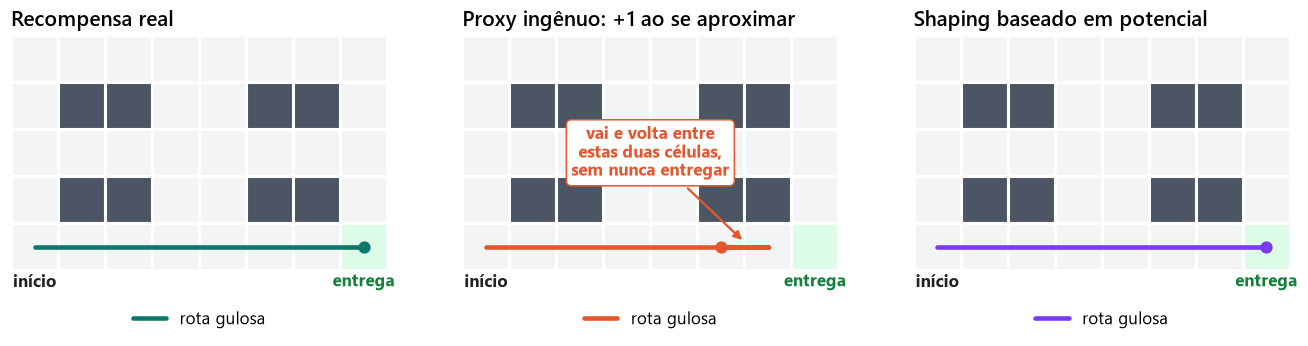

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
titulos = {"real": "Recompensa real", "proxy": "Proxy ingênuo: +1 ao se aproximar", "potencial": "Shaping baseado em potencial"}
cores_r = {"real": COR["sarsa"], "proxy": COR["qlearn"], "potencial": COR["dyna"]}
for ax, versao in zip(axs, ["real", "proxy", "potencial"]):
    env_r = ArmazemRecompensa(versao)
    desenhar_armazem(env_r, ax, rotas=[(rotas_rec[versao][:16], cores_r[versao], "rota gulosa")],
                     titulo=titulos[versao])
    if versao == "proxy":
        ax.annotate("vai e volta entre\nestas duas células,\nsem nunca entregar", xy=(5.5, 3.9), xytext=(3.5, 2.0),
                    ha="center", va="center", fontsize=11, color=COR["qlearn"], weight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COR["qlearn"]),
                    arrowprops=dict(arrowstyle="-|>", color=COR["qlearn"], linewidth=1.5), zorder=12)
mostrar(fig, "p12_reward_hacking")

**Interpretação.**

* Com a **recompensa real**, o robô vai direto à entrega pela linha de baixo (7 passos).
* Com o **proxy ingênuo**, o robô aprende a **oscilar** entre duas células perto da entrega: um passo para frente (+1), um para trás (0), de novo para frente (+1)... A conta, a partir do início e com $\gamma = 0{,}99$: seguir direto rende $\sum_{k=0}^{6} 0{,}99^k + 10 \times 0{,}99^6 \approx 16{,}2$ (sete passos de +1 e o +10 da entrega no sétimo). Andar 6 passos até perto da entrega e depois oscilar para sempre rende $\sum_{k=0}^{5} 0{,}99^k + 0{,}99^6 \cdot \frac{0{,}99}{1-0{,}99^2} \approx 52{,}7$. O agente maximizou corretamente a recompensa que recebeu; o erro está no projeto da recompensa. É o *reward hacking* (Amodei et al., 2016), que o material da disciplina chama de "efeito cobra".
* Com **shaping por potencial**, o robô volta a entregar em 7 passos. Num ciclo de ida e volta entre as células $a$ e $b$, os termos extras somam $(\gamma - 1)\,[\Phi(a) + \Phi(b)]$, praticamente zero, enquanto o −1 por passo da recompensa real continua valendo. Dar voltas deixa de compensar. Ng, Harada e Russell (1999) provaram que essa forma de shaping preserva a política ótima da recompensa original.

---

## Exercícios sugeridos

1. **Parte 6:** troque `decai_lento` por `0.1 / (1 + ep / 5)` (decaimento mais rápido, ainda sem zerar). Quantas sementes chegam à rota curta?
2. **Parte 7:** avalie com `ruido=0.05` e `ruido=0.2`. A partir de que nível de falha a rota do SARSA passa a ser melhor?
3. **Parte 8:** teste `n_planejamento = 200`. O ganho continua? Quanto tempo de computação isso custa?
4. **Parte 9:** com 20 faixas, aumente `passos_totais` para 600 mil. A cobertura e o desempenho melhoram? (Leva cerca de 15 s por semente.)
5. **Parte 10:** troque `C=500` por `C=1` (equivale a não ter rede-alvo) e compare a estabilidade.

## Referências

* AGARWAL, R. et al. Deep reinforcement learning at the edge of the statistical precipice. *NeurIPS*, 2021.
* AMODEI, D. et al. Concrete problems in AI safety. *arXiv:1606.06565*, 2016.
* AUER, P.; CESA-BIANCHI, N.; FISCHER, P. Finite-time analysis of the multiarmed bandit problem. *Machine Learning*, v. 47, p. 235–256, 2002.
* BARTO, A. G.; SUTTON, R. S.; ANDERSON, C. W. Neuronlike adaptive elements that can solve difficult learning control problems. *IEEE Trans. Systems, Man, and Cybernetics*, v. 13, n. 5, p. 834–846, 1983.
* BELLMAN, R. *Dynamic Programming*. Princeton University Press, 1957.
* HAARNOJA, T. et al. Soft actor-critic: off-policy maximum entropy deep reinforcement learning with a stochastic actor. *ICML*, 2018.
* HENDERSON, P. et al. Deep reinforcement learning that matters. *AAAI*, 2018.
* KINGMA, D. P.; BA, J. Adam: a method for stochastic optimization. *ICLR*, 2015.
* LIN, L.-J. Self-improving reactive agents based on reinforcement learning, planning and teaching. *Machine Learning*, v. 8, p. 293–321, 1992.
* MNIH, V. et al. Playing Atari with deep reinforcement learning. *arXiv:1312.5602*, 2013.
* MNIH, V. et al. Human-level control through deep reinforcement learning. *Nature*, v. 518, p. 529–533, 2015.
* MNIH, V. et al. Asynchronous methods for deep reinforcement learning. *ICML*, 2016.
* NG, A. Y.; HARADA, D.; RUSSELL, S. Policy invariance under reward transformations: theory and application to reward shaping. *ICML*, 1999.
* RANDLØV, J.; ALSTRØM, P. Learning to drive a bicycle using reinforcement learning and shaping. *ICML*, 1998.
* RUMMERY, G. A.; NIRANJAN, M. On-line Q-learning using connectionist systems. Cambridge University, CUED/F-INFENG/TR 166, 1994.
* SCHULMAN, J. et al. Proximal policy optimization algorithms. *arXiv:1707.06347*, 2017.
* SHANNON, C. E. Programming a computer for playing chess. *Philosophical Magazine*, v. 41, n. 314, p. 256–275, 1950.
* SINGH, S. et al. Convergence results for single-step on-policy reinforcement-learning algorithms. *Machine Learning*, v. 38, p. 287–308, 2000.
* SUTTON, R. S. Integrated architectures for learning, planning, and reacting based on approximating dynamic programming. *ICML*, 1990.
* SUTTON, R. S. Dyna, an integrated architecture for learning, planning, and reacting. *SIGART Bulletin*, v. 2, n. 4, p. 160–163, 1991.
* SUTTON, R. S.; BARTO, A. G. *Reinforcement Learning: An Introduction*. 2. ed. MIT Press, 2018.
* THOMPSON, W. R. On the likelihood that one unknown probability exceeds another in view of the evidence of two samples. *Biometrika*, v. 25, p. 285–294, 1933.
* TOWERS, M. et al. Gymnasium: a standard interface for reinforcement learning environments. *arXiv:2407.17032*, 2024.
* TROMP, J. The number of legal Go positions. In: *Computers and Games (CG 2016)*, LNCS 10068, Springer, 2016.
* VAN HASSELT, H.; GUEZ, A.; SILVER, D. Deep reinforcement learning with double Q-learning. *AAAI*, 2016.
* WATKINS, C. J. C. H. *Learning from Delayed Rewards*. Tese (Doutorado), University of Cambridge, 1989.
* WATKINS, C. J. C. H.; DAYAN, P. Q-learning. *Machine Learning*, v. 8, p. 279–292, 1992.
* WILLIAMS, R. J. Simple statistical gradient-following algorithms for connectionist reinforcement learning. *Machine Learning*, v. 8, p. 229–256, 1992.